# SSV JAMA Pro Workflow

JAMA Pro reproducibility extension for cross-dataset batch-aware evaluation. This notebook preserves the baseline JAMA broad scenario definitions and adds the shared Pro QC, sample-wise poor-marker diagnostics, and optional bidirectional Pro evaluation layer.


## Imports, paths, and Pro controls


In [10]:
from __future__ import annotations

from contextlib import redirect_stdout
import io
import json
import os
from pathlib import Path
import re
import sys
from time import perf_counter

try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = None

    def display(value):
        print(value)

try:
    import matplotlib.pyplot as plt
except ImportError as exc:
    raise ImportError("matplotlib is required for JAMA Pro diagnostic plots.") from exc


def resolve_base_dir() -> Path:
    cwd = Path.cwd().resolve()
    required = {"expression_matrix.csv", "expressed_mirnas.txt", "eTable1.xlsx", "SSV Jama.Rmd"}
    if cwd.name == "2Jama" and required <= {path.name for path in cwd.iterdir()}:
        return cwd
    candidate = cwd / "2Jama"
    if candidate.exists() and required <= {path.name for path in candidate.iterdir()}:
        return candidate.resolve()
    raise RuntimeError("Launch this notebook from 2Jama or from its parent RNASeq_with_Python directory.")


BASE_DIR = resolve_base_dir()
EXPRESSION_PATH = BASE_DIR / "expression_matrix.csv"
EXPRESSED_MIRNAS_PATH = BASE_DIR / "expressed_mirnas.txt"
CLINICAL_PATH = BASE_DIR / "eTable1.xlsx"
PRO_NOTEBOOK_PATH = BASE_DIR / "SSV_Jama_Python_pro.ipynb"
BASELINE_SOURCE_CANDIDATES = (
    BASE_DIR / "SSV_Jama_Python(5).ipynb",
    BASE_DIR / "SSV_Jama_Python.ipynb",
)
BASELINE_SOURCE_NOTEBOOK = next((path for path in BASELINE_SOURCE_CANDIDATES if path.exists()), BASELINE_SOURCE_CANDIDATES[-1])

PRO_RUNTIME_CANDIDATES = (
    BASE_DIR.parent / "SSV_Python_Reproduction_pro.ipynb",
    BASE_DIR.parent / "1Yokoi" / "SSV_Python_Reproduction_pro.ipynb",
)
PRO_RUNTIME_NOTEBOOK = next((path for path in PRO_RUNTIME_CANDIDATES if path.exists()), PRO_RUNTIME_CANDIDATES[0])

JAMA_STRUCTURE_SEED = 12345
UMAP_RANDOM_STATE = 1
KMEANS_RANDOM_STATE = 12345
KMEANS_N_INIT = 50
N_BATCHES = 3
EARLY_BATCH_ID = 2

S1_S2_POOR_RANGE = (3.9, 5.9)
S1_S2_POSITIVE_MEAN_CUTOFF = 7.0
S3_POOR_RANGE = (4.3, 5.3)
S3_TOP_N_FEATURES = 200

DATA_TYPE_RNASEQ = False
JAMA_PRO_OUTPUT_ROOT = BASE_DIR / "results_pro_jama"
JAMA_QC_BOXPLOT_MAX_SAMPLES_PER_STRATUM = 80

for expected_path in (EXPRESSION_PATH, EXPRESSED_MIRNAS_PATH, CLINICAL_PATH, PRO_RUNTIME_NOTEBOOK, BASELINE_SOURCE_NOTEBOOK):
    assert expected_path.exists(), f"Missing required input: {expected_path}"

print(f"BASE_DIR: {BASE_DIR}")
print(f"Baseline JAMA source: {BASELINE_SOURCE_NOTEBOOK.name}")
print(f"Shared Pro runtime: {PRO_RUNTIME_NOTEBOOK}")
print(f"JAMA Pro output root: {JAMA_PRO_OUTPUT_ROOT}")


BASE_DIR: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama
Baseline JAMA source: SSV_Jama_Python.ipynb
Shared Pro runtime: C:\Users\apple\Desktop\RNASeq_with_Python\1Yokoi\SSV_Python_Reproduction_pro.ipynb
JAMA Pro output root: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama


## Load shared Pro runtime

The generic Pro runtime is loaded from `SSV_Python_Reproduction_pro.ipynb`. This notebook does not execute another dataset-specific notebook as a runtime.


,repetition,split_percentage,meta_batch_1_labels,meta_batch_2_labels,meta_batch_1_n_before_balance,meta_batch_2_n_before_balance,meta_batch_1_n_after_balance,meta_batch_2_n_after_balance,train_1_n,train_2_n,train_n,test_n,overlap_n
0,1,50,batch_1|batch_3,batch_2|batch_4,11,9,9,9,4,4,8,10,0
1,1,100,batch_1|batch_3,batch_2|batch_4,11,9,9,9,9,0,9,9,0
2,2,50,batch_2|batch_4,batch_1|batch_3,9,11,9,9,4,4,8,10,0
3,2,100,batch_2|batch_4,batch_1|batch_3,9,11,9,9,9,0,9,9,0


,method,status,inner_cv_error,outer_test_error
0,svm,fit/predict passed,0.15,0.0
1,lasso,fit/predict passed,0.05,0.1
2,xgb,fit/predict passed,0.20,0.0
3,knn,fit/predict passed,0.10,0.1
4,rf,fit/predict passed,0.10,0.1


,repetition,split_percentage,normalization_method,classifier_method,inner_cv_error,outer_test_error,majority_baseline_error,balanced_error,status
0,1,50,non,knn,0.200000,0.375000,0.437500,0.380952,success
1,1,50,non,svm,0.166667,0.437500,0.437500,0.388889,success
2,1,50,qn,knn,0.133333,0.375000,0.437500,0.349206,success
3,1,50,qn,svm,0.133333,0.437500,0.437500,0.388889,success
4,1,100,non,knn,0.333333,0.400000,0.466667,0.383929,success
5,1,100,non,svm,0.266667,0.133333,0.466667,0.133929,success
6,1,100,qn,knn,0.133333,0.266667,0.466667,0.285714,success
7,1,100,qn,svm,0.333333,0.200000,0.466667,0.196429,success


,split_percentage,normalization_method,classifier_method,n_requested,n_success,n_failed,failure_rate,mean_outer_error,sd_outer_error,se_outer_error
0,50,non,knn,1,1,0,0.0,0.375000,NaN,NaN
1,50,non,svm,1,1,0,0.0,0.437500,NaN,NaN
2,50,qn,knn,1,1,0,0.0,0.375000,NaN,NaN
3,50,qn,svm,1,1,0,0.0,0.437500,NaN,NaN
4,100,non,knn,1,1,0,0.0,0.400000,NaN,NaN
5,100,non,svm,1,1,0,0.0,0.133333,NaN,NaN
6,100,qn,knn,1,1,0,0.0,0.266667,NaN,NaN
7,100,qn,svm,1,1,0,0.0,0.200000,NaN,NaN


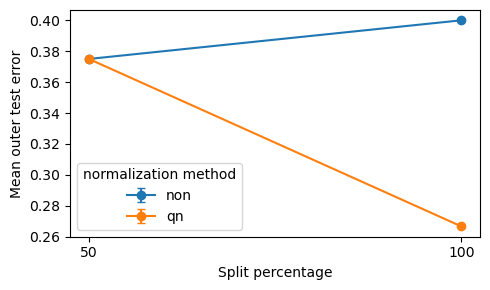

,R component,Python counterpart,status,note
0,Data contract,MolecularDataset,implemented,features x samples; exact label alignment
1,ml_sum batch construction,construct_meta_batches(),implemented,temporal and raw-batch random modes
2,batch_balance,balance_meta_batches(),implemented,downsamples larger meta-batch
3,split_combination,split_meta_batches(),implemented,s% batch1 plus 100-s% batch2
4,times / repetitions,generate_split_experiments(),implemented,meta-batch assignment fixed per repetition; ba...
5,quant.norm,normalize_transformed_qn(),implemented,train QN plus training-derived test mapping
6,med.norm,median_normalize(),implemented,global training median reference
7,vs.norm,normalize_vsn(),implemented with Python equivalent,training-fitted feature-wise asinh location/sc...
8,RNA non,identity_normalize(),implemented,literal copy without dtype conversion
9,harmon.method.TC,normalize_tc(),implemented,CPM total-count scaling


Shared Pro runtime loaded.
Required objects: MolecularDataset, validate_molecular_dataset, summarize_batch_structure, plot_poor_marker_samplewise_boxplot, run_ssv_pro_experiment_batch, run_ssv_pro_bidirectional, aggregate_equal_weight_directions, save_ssv_pro_artifacts


In [11]:
_RUNTIME_REQUIRED = (
    "MolecularDataset",
    "validate_molecular_dataset",
    "summarize_batch_structure",
    "plot_poor_marker_samplewise_boxplot",
    "run_ssv_pro_experiment_batch",
    "run_ssv_pro_bidirectional",
    "aggregate_equal_weight_directions",
    "save_ssv_pro_artifacts",
)


def load_shared_pro_runtime(path: Path):
    namespace = globals()
    notebook = json.loads(path.read_text(encoding="utf-8"))
    with redirect_stdout(io.StringIO()):
        for i, cell in enumerate(notebook["cells"]):
            if cell.get("cell_type") != "code":
                continue
            source = "".join(cell.get("source", []))
            exec(compile(source, f"{path.name}:cell{i}", "exec"), namespace)
    missing = [name for name in _RUNTIME_REQUIRED if name not in namespace]
    if missing:
        raise RuntimeError(f"Shared Pro runtime did not define: {missing}")
    if "PRO_METRICS" in namespace:
        assert {"raw_error", "balanced_error"} <= set(namespace["PRO_METRICS"])
    plt.close("all")


load_shared_pro_runtime(PRO_RUNTIME_NOTEBOOK)
print("Shared Pro runtime loaded.")
print("Required objects:", ", ".join(_RUNTIME_REQUIRED))


## Baseline JAMA loading helpers


In [12]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from umap import UMAP


def r_make_name(value: object) -> str:
    text = str(value)
    text = re.sub(r"[^0-9A-Za-z_.]", ".", text)
    if not re.match(r"^[A-Za-z.]", text) or re.match(r"^\.[0-9]", text):
        text = f"X{text}"
    reserved = {"if", "else", "repeat", "while", "function", "for", "in", "next", "break"}
    return f"{text}." if text in reserved else text


def sample_group(sample: str) -> str | None:
    if sample.startswith("Healthy.control."):
        return "HC"
    if sample.startswith("NTLD."):
        return "NTLD"
    if sample.startswith("LCa."):
        return "LCa"
    if sample.startswith("OD."):
        return "OD"
    return None


def sample_index(sample: str) -> int:
    match = re.search(r"\.(\d+)$", sample)
    if not match:
        raise ValueError(f"Cannot parse trailing sample index from {sample!r}")
    return int(match.group(1))


def load_expression_table(apply_expressed_filter: bool = False):
    data_all = pd.read_csv(EXPRESSION_PATH, sep="\t")
    if data_all.columns[0] != "miRNA":
        raise ValueError("expression_matrix.csv must have miRNA as the first column")
    data_all = data_all.rename(columns={name: r_make_name(name) for name in data_all.columns})
    if not data_all["miRNA"].is_unique:
        raise ValueError("miRNA feature names must be unique")
    if apply_expressed_filter:
        expressed = pd.read_csv(EXPRESSED_MIRNAS_PATH, header=None, sep=r"\s+", engine="python")[0].astype(str)
        data_all = data_all.loc[data_all["miRNA"].astype(str).isin(set(expressed))].copy()
        if data_all.empty:
            raise ValueError("expressed_mirnas.txt filter removed all features")
    return data_all


def numeric_expression_from_table(data_all):
    expr_raw = data_all.drop(columns=["miRNA"]).apply(pd.to_numeric, errors="raise")
    keep_samples = expr_raw.isna().sum(axis=0).eq(0)
    expr_clean = expr_raw.loc[:, keep_samples].copy()
    if expr_clean.empty:
        raise ValueError("No expression samples remain after NA-column removal")
    if not np.isfinite(expr_clean.to_numpy(dtype=float)).all():
        raise ValueError("Expression matrix contains non-finite values before log transform")
    return expr_clean


def make_expression_frame(values, feature_ids, sample_ids):
    expression = pd.DataFrame(values, index=pd.Index(feature_ids, name="miRNA"), columns=pd.Index(sample_ids, name="sample"))
    if not expression.index.is_unique:
        raise ValueError("Expression feature IDs are not unique")
    if not expression.columns.is_unique:
        raise ValueError("Expression sample IDs are not unique")
    return expression


def build_sample_info(sample_ids, clinical_meta=None):
    sample_info = pd.DataFrame({"Sample": list(sample_ids)})
    sample_info["ID"] = sample_info["Sample"].map(sample_group)
    sample_info["Sample_index"] = sample_info["Sample"].map(sample_index)
    if sample_info["ID"].isna().any():
        missing = sample_info.loc[sample_info["ID"].isna(), "Sample"].head().tolist()
        raise ValueError(f"Unexpected sample name pattern: {missing}")
    if clinical_meta is not None:
        group_col = clinical_meta.columns[6]
        stage_col = clinical_meta.columns[7]
        clinical = clinical_meta.copy()
        clinical["Group_clean"] = clinical[group_col].astype(str)
        clinical["Stage"] = pd.to_numeric(clinical[stage_col], errors="coerce")
        clinical["Group_index"] = clinical.groupby("Group_clean").cumcount() + 1
        sample_info = sample_info.merge(
            clinical,
            left_on=["ID", "Sample_index"],
            right_on=["Group_clean", "Group_index"],
            how="left",
            validate="one_to_one",
        )
        lca_missing_stage = sample_info.loc[sample_info["ID"].eq("LCa"), "Stage"].isna().sum()
        if lca_missing_stage == sample_info["ID"].eq("LCa").sum():
            raise ValueError("Clinical stage mapping failed for all LCa samples")
    return sample_info


def remap_three_kmeans_batches(raw_labels, kmeans_centers):
    centers = pd.DataFrame(kmeans_centers, columns=["UMAP1", "UMAP2"])
    centers["cluster"] = range(N_BATCHES)
    global_center = centers[["UMAP1", "UMAP2"]].mean(axis=0)
    centers["dist_to_center"] = (((centers[["UMAP1", "UMAP2"]] - global_center) ** 2).sum(axis=1)) ** 0.5
    middle_cluster = int(centers.loc[centers["dist_to_center"].idxmin(), "cluster"])
    outer_clusters = centers.loc[centers["cluster"].ne(middle_cluster)].sort_values("UMAP1")["cluster"].tolist()
    cluster_map = {outer_clusters[0]: 1, middle_cluster: 2, outer_clusters[1]: 3}
    batch_labels = [cluster_map[int(label)] for label in raw_labels]
    if set(batch_labels) != {1, 2, 3}:
        raise ValueError("KMeans batch remapping did not produce labels 1, 2, and 3")
    return batch_labels


def infer_jama_batches(expression, poor_data, sample_info):
    umap_input = poor_data.T.copy()
    if not umap_input.index.equals(expression.columns):
        raise ValueError("UMAP input sample IDs do not match expression sample IDs")
    if not np.isfinite(umap_input.to_numpy()).all():
        raise ValueError("UMAP input contains non-finite values")
    embedding = UMAP(n_components=4, random_state=UMAP_RANDOM_STATE).fit_transform(umap_input)
    umap_frame = pd.DataFrame(embedding, index=umap_input.index, columns=[f"UMAP{i}" for i in range(1, 5)])
    kmeans_input = umap_frame[["UMAP1", "UMAP2"]]
    kmeans = KMeans(n_clusters=N_BATCHES, n_init=KMEANS_N_INIT, random_state=KMEANS_RANDOM_STATE)
    raw_labels = kmeans.fit_predict(kmeans_input)
    batch_labels = pd.Series(
        remap_three_kmeans_batches(raw_labels, kmeans.cluster_centers_),
        index=umap_frame.index,
        name="batch",
    )
    layout = umap_frame.reset_index(names="Sample").merge(
        sample_info[["Sample", "ID"] + (["Stage"] if "Stage" in sample_info.columns else [])],
        on="Sample",
        how="left",
        validate="one_to_one",
    )
    layout["batch"] = batch_labels.loc[layout["Sample"]].to_numpy(dtype=int)
    if layout["ID"].isna().any():
        raise ValueError("UMAP layout lost biological group labels")
    return layout, batch_labels



def make_jama_meta_batches(inferred_batch_labels):
    """Map original JAMA inferred batches to the two Pro meta-batches.

    Source-of-truth JAMA/R-style temporal semantics:
    inferred batch 2 is early/training-side and maps to batch_1;
    inferred batches 1 and 3 are late/test-side and map to batch_2.
    """
    if not isinstance(inferred_batch_labels, pd.Series):
        raise TypeError("inferred_batch_labels must be a pandas Series")
    labels = inferred_batch_labels.copy()
    if labels.isna().any():
        raise ValueError("inferred batch labels must not contain missing values")
    numeric_labels = pd.to_numeric(labels, errors="raise").astype(int)
    observed = set(numeric_labels.unique())
    if not observed <= {1, 2, 3}:
        raise ValueError(f"Unexpected JAMA inferred batch labels: {sorted(observed)}")
    if observed != {1, 2, 3}:
        raise ValueError(f"Each JAMA scenario must retain inferred batches 1, 2, and 3 before Pro mapping; observed {sorted(observed)}")
    meta = numeric_labels.map({2: "batch_1", 1: "batch_2", 3: "batch_2"}).rename("batch")
    meta.index = inferred_batch_labels.index
    if set(meta.unique()) != {"batch_1", "batch_2"}:
        raise ValueError("JAMA meta-batch mapping must produce exactly batch_1 and batch_2")
    if not meta.index.equals(inferred_batch_labels.index):
        raise ValueError("JAMA meta-batch mapping changed sample order")
    return meta


def validate_jama_meta_batch_mapping(inferred_batch_labels, meta_batch_labels, class_labels, expression, scenario):
    if not expression.columns.equals(inferred_batch_labels.index):
        raise ValueError(f"{scenario}: expression and inferred batch labels are not aligned")
    if not expression.columns.equals(meta_batch_labels.index):
        raise ValueError(f"{scenario}: expression and meta-batch labels are not aligned")
    if not expression.columns.equals(class_labels.index):
        raise ValueError(f"{scenario}: expression and class labels are not aligned")
    if len(meta_batch_labels) != len(inferred_batch_labels) or meta_batch_labels.index.has_duplicates:
        raise ValueError(f"{scenario}: meta-batch mapping lost or duplicated samples")
    if set(meta_batch_labels.unique()) != {"batch_1", "batch_2"}:
        raise ValueError(f"{scenario}: Pro dataset must contain exactly batch_1 and batch_2")
    if not meta_batch_labels.loc[inferred_batch_labels.astype(int).eq(EARLY_BATCH_ID)].eq("batch_1").all():
        raise ValueError(f"{scenario}: inferred batch {EARLY_BATCH_ID} must map to batch_1")
    if not meta_batch_labels.loc[inferred_batch_labels.astype(int).isin([1, 3])].eq("batch_2").all():
        raise ValueError(f"{scenario}: inferred batches 1 and 3 must map to batch_2")
    contingency = pd.crosstab(meta_batch_labels.rename("meta_batch"), class_labels.rename("class"))
    if (contingency == 0).any().any():
        print(f"WARNING: {scenario} has at least one empty meta-batch x class cell; interpret transfer estimates with identifiability caution.")
    return contingency


## Scenario 1 / 2 original JAMA definitions and inferred batch

Scenario 1/2 preserve the baseline JAMA `log2(raw)` analysis scale, the JAMA poor-marker range, the broad positive feature cutoff, and UMAP1/UMAP2 KMeans batch inference.


In [13]:
s12_data_all = load_expression_table(apply_expressed_filter=False)
s12_expr_clean = numeric_expression_from_table(s12_data_all)
s12_expression = make_expression_frame(np.log2(s12_expr_clean.to_numpy(dtype=float)), s12_data_all["miRNA"], s12_expr_clean.columns)
if not np.isfinite(s12_expression.to_numpy(dtype=float)).all():
    raise ValueError("Scenario 1/2 log2(raw) produced non-finite values")

s12_sample_info = build_sample_info(s12_expression.columns)
s12_feature_means = s12_expression.mean(axis=1)
s12_poor_mask = (s12_feature_means > S1_S2_POOR_RANGE[0]) & (s12_feature_means < S1_S2_POOR_RANGE[1])
s12_positive_mask = s12_feature_means > S1_S2_POSITIVE_MEAN_CUTOFF
s12_poor_data = s12_expression.loc[s12_poor_mask].copy()
s12_positive_data = s12_expression.loc[s12_positive_mask].copy()
s12_layout_df, s12_batch_labels = infer_jama_batches(s12_expression, s12_poor_data, s12_sample_info)

s1_metadata = s12_layout_df.set_index("Sample").loc[s12_expression.columns].copy()
s1_metadata["modeling_label"] = s1_metadata["ID"].where(s1_metadata["ID"].eq("LCa"), "Non-LCa")
s1_class_labels = s1_metadata["ID"].eq("LCa").astype(int).rename("class")
s1_batch_labels = s12_batch_labels.loc[s12_expression.columns].rename("batch")
s1_broad_dataset = MolecularDataset(s12_positive_data, s1_class_labels, s1_batch_labels)
validate_molecular_dataset(s1_broad_dataset)

s2_keep_samples = s12_layout_df.loc[s12_layout_df["ID"].isin(["LCa", "NTLD"]), "Sample"]
s2_metadata = s12_layout_df.set_index("Sample").loc[s2_keep_samples].copy()
s2_metadata["modeling_label"] = s2_metadata["ID"].map({"LCa": "LCa", "NTLD": "NTLD"})
s2_class_labels = s2_metadata["ID"].eq("LCa").astype(int).rename("class")
s2_batch_labels = s12_batch_labels.loc[s2_metadata.index].rename("batch")
s2_broad_expression = s12_positive_data.loc[:, s2_metadata.index].copy()
s2_broad_dataset = MolecularDataset(s2_broad_expression, s2_class_labels, s2_batch_labels)
validate_molecular_dataset(s2_broad_dataset)

print("Scenario 1/2 JAMA definitions complete.")
print(f"Scenario 1 broad: {s1_broad_dataset.expression.shape[0]} features x {s1_broad_dataset.expression.shape[1]} samples")
print(f"Scenario 2 broad: {s2_broad_dataset.expression.shape[0]} features x {s2_broad_dataset.expression.shape[1]} samples")
print(f"Scenario 1/2 poor markers: {s12_poor_data.shape[0]}")
display(pd.crosstab(s12_layout_df["batch"], s12_layout_df["ID"]))


C:\Users\apple\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Scenario 1/2 JAMA definitions complete.
Scenario 1 broad: 152 features x 2694 samples
Scenario 2 broad: 152 features x 1119 samples
Scenario 1/2 poor markers: 268


ID,HC,LCa,NTLD,OD
batch,,,,
1,70,18,0,98
2,665,507,327,642
3,18,21,246,82


## Scenario 3 original JAMA definitions and inferred batch

Scenario 3 preserves the baseline JAMA expressed-miRNA filter, `log2(raw + 1)` analysis scale, Scenario 3 poor-marker range, top-N broad features, and early-stage LCa vs Non-LCa stage filter.


In [14]:
s3_data_all = load_expression_table(apply_expressed_filter=True)
s3_expr_clean = numeric_expression_from_table(s3_data_all)
s3_clinical_meta = pd.read_excel(CLINICAL_PATH)
s3_expression = make_expression_frame(np.log2(s3_expr_clean.to_numpy(dtype=float) + 1.0), s3_data_all["miRNA"], s3_expr_clean.columns)
s3_sample_info = build_sample_info(s3_expression.columns, clinical_meta=s3_clinical_meta)

s3_feature_means = s3_expression.mean(axis=1)
s3_poor_mask = (s3_feature_means > S3_POOR_RANGE[0]) & (s3_feature_means < S3_POOR_RANGE[1])
s3_top_feature_ids = s3_feature_means.sort_values(ascending=False).index[: min(S3_TOP_N_FEATURES, len(s3_feature_means))]
s3_poor_data_all = s3_expression.loc[s3_poor_mask].copy()
s3_positive_data_all = s3_expression.loc[s3_top_feature_ids].copy()
s3_layout_df, s3_batch_labels_all = infer_jama_batches(s3_expression, s3_poor_data_all, s3_sample_info)

s3_layout_all = s3_layout_df.set_index("Sample").loc[s3_expression.columns].copy()
s3_keep_mask = (s3_layout_all["ID"].eq("LCa") & s3_layout_all["Stage"].isin([1, 2])) | s3_layout_all["ID"].ne("LCa")
s3_metadata = s3_layout_all.loc[s3_keep_mask].copy()
s3_excluded_lca = s3_layout_all.loc[s3_layout_all["ID"].eq("LCa") & ~s3_layout_all.index.isin(s3_metadata.index)].copy()
if s3_excluded_lca["Stage"].isin([1, 2]).any():
    raise ValueError("Scenario 3 accidentally excluded an early-stage LCa sample")
s3_metadata["modeling_label"] = s3_metadata.apply(
    lambda row: "Early-stage LCa" if row["ID"] == "LCa" and row["Stage"] in (1, 2) else "Non-LCa",
    axis=1,
)

s3_class_labels = s3_metadata["modeling_label"].eq("Early-stage LCa").astype(int).rename("class")
s3_batch_labels = s3_metadata["batch"].astype(int).rename("batch")
s3_broad_expression = s3_positive_data_all.loc[:, s3_metadata.index].copy()
s3_poor_data = s3_poor_data_all.loc[:, s3_metadata.index].copy()
s3_broad_dataset = MolecularDataset(s3_broad_expression, s3_class_labels, s3_batch_labels)
validate_molecular_dataset(s3_broad_dataset)

print("Scenario 3 JAMA definitions complete.")
print(f"Scenario 3 broad: {s3_broad_dataset.expression.shape[0]} features x {s3_broad_dataset.expression.shape[1]} samples")
print(f"Scenario 3 poor markers: {s3_poor_data.shape[0]}")
print(f"Retained early-stage LCa: {int(s3_class_labels.sum())}")
print(f"Retained non-LCa: {int((s3_class_labels == 0).sum())}")
print(f"Excluded LCa: {s3_excluded_lca.shape[0]}")
display(s3_layout_all.loc[s3_layout_all["ID"].eq("LCa"), "Stage"].value_counts(dropna=False).sort_index().rename("n").to_frame())


C:\Users\apple\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Scenario 3 JAMA definitions complete.
Scenario 3 broad: 200 features x 2319 samples
Scenario 3 poor markers: 135
Retained early-stage LCa: 171
Retained non-LCa: 2148
Excluded LCa: 375


,n
Stage,
1.0,65
2.0,106
3.0,118
4.0,118
NaN,139


UMAP output directories
-----------------------
Shared QC : C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\umap_qc
Scenario 1: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s1_broad
Scenario 2: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s2_broad
Scenario 3: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s3_broad

1. S1/S2 shared UMAP — biological groups


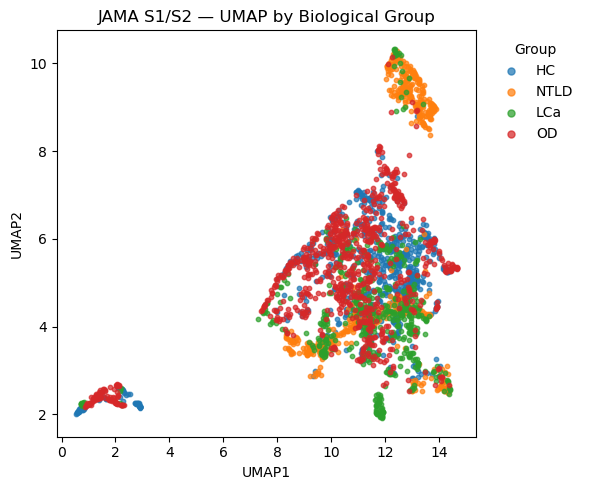

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\umap_qc\s12_biological_group_umap.png

2. S1/S2 shared UMAP — inferred batch


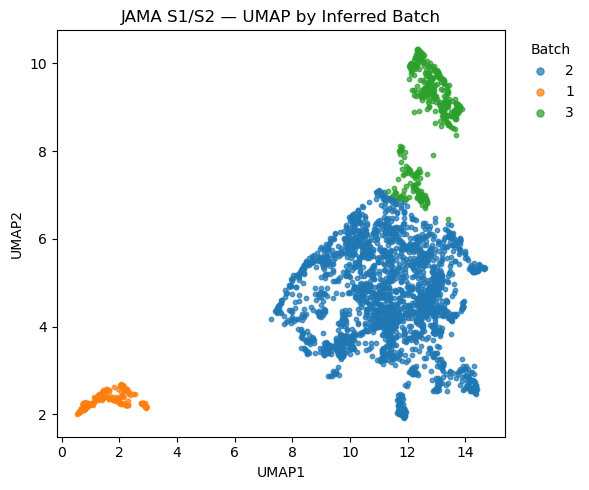

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\umap_qc\s12_inferred_batch_umap.png

3. Scenario 1 — LCa vs Non-LCa


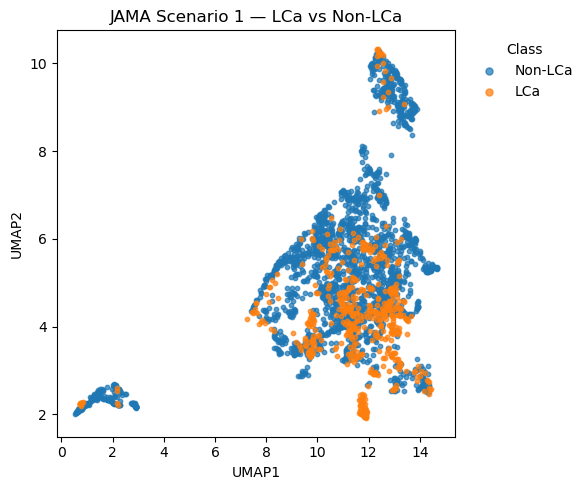

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s1_broad\scenario_class_umap.png

4. Scenario 2 — LCa vs NTLD


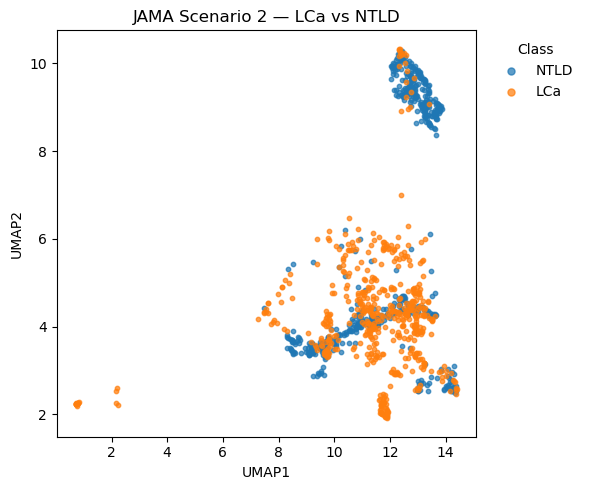

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s2_broad\scenario_class_umap.png

5. Scenario 3 — biological groups


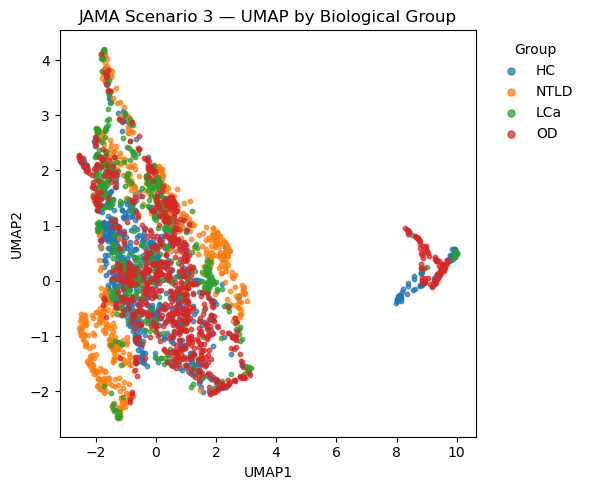

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\umap_qc\s3_biological_group_umap.png

6. Scenario 3 — inferred batch


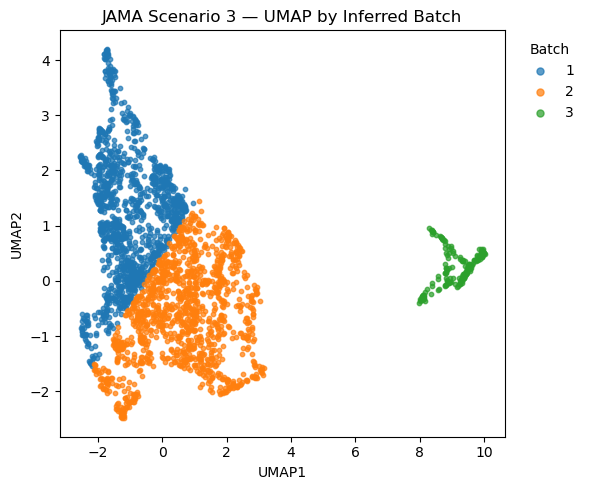

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\umap_qc\s3_inferred_batch_umap.png

7. Scenario 3 — Early-stage LCa vs Non-LCa


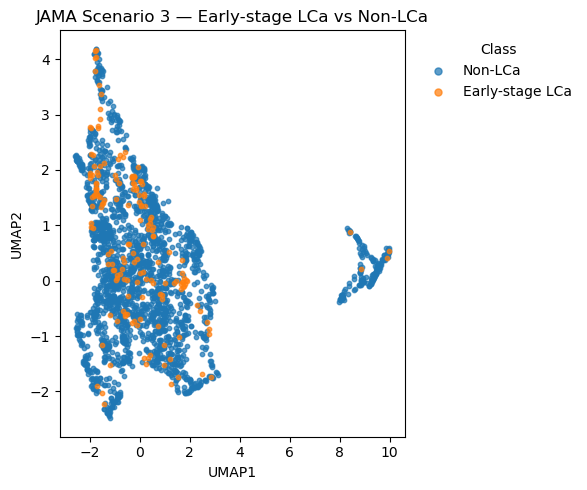

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s3_broad\scenario_class_umap.png

8. JAMA Pro Scenario 1 — meta-batch


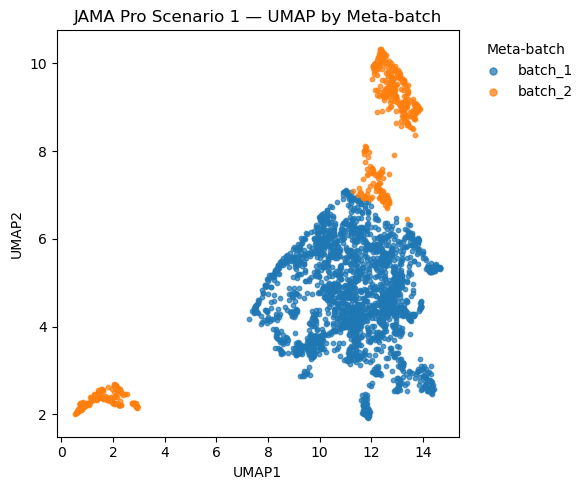

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s1_broad\meta_batch_umap.png

9. JAMA Pro Scenario 2 — meta-batch


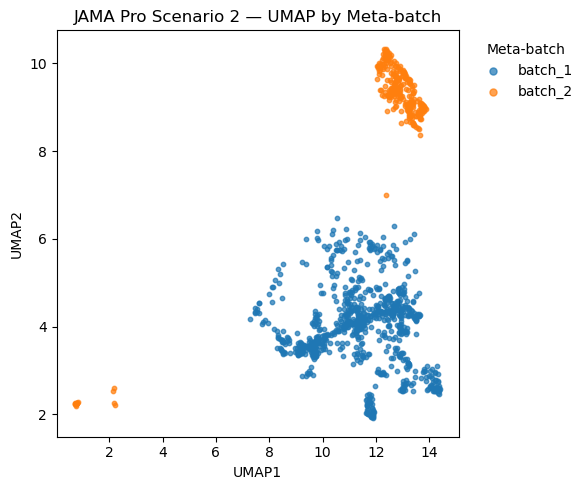

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s2_broad\meta_batch_umap.png

10. JAMA Pro Scenario 3 — meta-batch


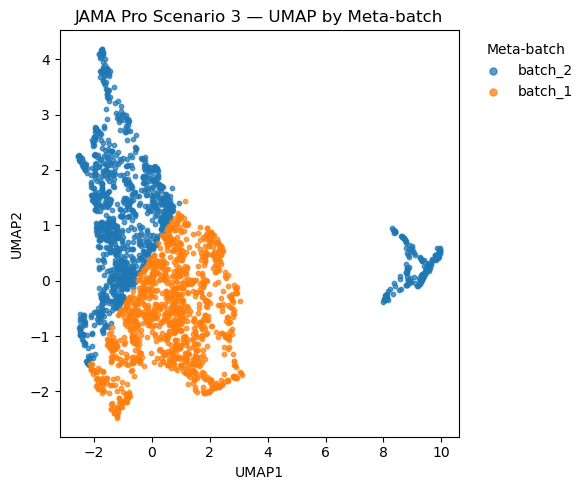

Saved: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\jama_pro_s3_broad\meta_batch_umap.png

JAMA / JAMA Pro UMAP ARTIFACT AUDIT
PASS — umap_qc\s12_biological_group_umap.png
PASS — umap_qc\s12_inferred_batch_umap.png
PASS — umap_qc\s3_biological_group_umap.png
PASS — umap_qc\s3_inferred_batch_umap.png
PASS — jama_pro_s1_broad\scenario_class_umap.png
PASS — jama_pro_s2_broad\scenario_class_umap.png
PASS — jama_pro_s3_broad\scenario_class_umap.png
PASS — jama_pro_s1_broad\meta_batch_umap.png
PASS — jama_pro_s2_broad\meta_batch_umap.png
PASS — jama_pro_s3_broad\meta_batch_umap.png
------------------------------------------------------------------------
PASS — all expected UMAP figures were saved.
Root: C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama


In [29]:
# ======================================================================
# JAMA / JAMA Pro — UMAP QC plots
# Display + save into the existing JAMA Pro output tree.
#
# IMPORTANT:
# - Uses existing UMAP coordinates only.
# - Does NOT rerun UMAP.
# - Does NOT rerun any classifier / JAMA Pro experiment.
# ======================================================================

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


# ======================================================================
# 0. Output paths
# ======================================================================

# All UMAP figures remain inside the existing JAMA Pro output root.
UMAP_SHARED_DIR = JAMA_PRO_OUTPUT_ROOT / "umap_qc"
UMAP_SHARED_DIR.mkdir(parents=True, exist_ok=True)


def get_experiment_output_dir(experiment_name):
    """
    Resolve the scenario-specific directory using the actual output_name
    stored in JAMA_PRO_EXPERIMENTS.
    """
    if experiment_name not in JAMA_PRO_EXPERIMENTS:
        raise KeyError(
            f"{experiment_name!r} not found in JAMA_PRO_EXPERIMENTS."
        )

    entry = JAMA_PRO_EXPERIMENTS[experiment_name]

    if "output_name" not in entry:
        raise KeyError(
            f"'output_name' missing from "
            f"JAMA_PRO_EXPERIMENTS[{experiment_name!r}]"
        )

    output_dir = JAMA_PRO_OUTPUT_ROOT / entry["output_name"]
    output_dir.mkdir(parents=True, exist_ok=True)

    return output_dir


S1_UMAP_DIR = get_experiment_output_dir("s1_broad")
S2_UMAP_DIR = get_experiment_output_dir("s2_broad")
S3_UMAP_DIR = get_experiment_output_dir("s3_broad")


print("UMAP output directories")
print("-----------------------")
print(f"Shared QC : {UMAP_SHARED_DIR}")
print(f"Scenario 1: {S1_UMAP_DIR}")
print(f"Scenario 2: {S2_UMAP_DIR}")
print(f"Scenario 3: {S3_UMAP_DIR}")


# ======================================================================
# 1. Shared Yokoi-style UMAP plotting helper
# ======================================================================

def plot_umap_by_series(
    umap_frame,
    color_series,
    title,
    legend_title,
    save_path,
):
    """
    Yokoi-style UMAP plot.

    The plot is:
    1. displayed inline;
    2. saved to save_path.

    Existing UMAP1 / UMAP2 coordinates are reused.
    """

    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    color_series = pd.Series(
        color_series,
        index=umap_frame.index,
    )

    plot_df = pd.DataFrame(
        {
            "UMAP1": umap_frame["UMAP1"].to_numpy(),
            "UMAP2": umap_frame["UMAP2"].to_numpy(),
            "group": color_series.astype(str).to_numpy(),
        },
        index=umap_frame.index,
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    for group in pd.unique(plot_df["group"]):
        mask = plot_df["group"].eq(group)

        ax.scatter(
            plot_df.loc[mask, "UMAP1"],
            plot_df.loc[mask, "UMAP2"],
            s=10,
            alpha=0.72,
            label=str(group),
        )

    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_title(title)

    ax.legend(
        title=legend_title,
        frameon=False,
        markerscale=1.6,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()

    # Save before plt.show()
    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")


# ======================================================================
# 2. Prepare shared S1/S2 UMAP
# ======================================================================

if "Sample" in s12_layout_df.columns:
    s12_umap = (
        s12_layout_df
        .set_index("Sample")
        .loc[s12_expression.columns]
        .copy()
    )
else:
    s12_umap = s12_layout_df.copy()

assert {"UMAP1", "UMAP2", "ID", "batch"} <= set(
    s12_umap.columns
)


# ======================================================================
# 3. S1/S2 shared UMAP — original biological groups
# ======================================================================

print("\n1. S1/S2 shared UMAP — biological groups")

plot_umap_by_series(
    umap_frame=s12_umap,
    color_series=s12_umap["ID"],
    title="JAMA S1/S2 — UMAP by Biological Group",
    legend_title="Group",
    save_path=(
        UMAP_SHARED_DIR
        / "s12_biological_group_umap.png"
    ),
)


# ======================================================================
# 4. S1/S2 shared UMAP — original inferred 3-batch structure
# ======================================================================

print("\n2. S1/S2 shared UMAP — inferred batch")

plot_umap_by_series(
    umap_frame=s12_umap,
    color_series=s12_umap["batch"].astype(str),
    title="JAMA S1/S2 — UMAP by Inferred Batch",
    legend_title="Batch",
    save_path=(
        UMAP_SHARED_DIR
        / "s12_inferred_batch_umap.png"
    ),
)


# ======================================================================
# 5. Scenario 1 — LCa vs Non-LCa
# ======================================================================

print("\n3. Scenario 1 — LCa vs Non-LCa")

assert "modeling_label" in s1_metadata.columns

s1_common = s12_umap.index.intersection(
    s1_metadata.index
)

if len(s1_common) == 0:
    raise ValueError(
        "No overlapping sample IDs between s12_umap "
        "and s1_metadata."
    )

s1_umap = s12_umap.loc[s1_common].copy()
s1_meta_aligned = s1_metadata.loc[s1_common].copy()

assert s1_umap.index.equals(
    s1_meta_aligned.index
)

plot_umap_by_series(
    umap_frame=s1_umap,
    color_series=s1_meta_aligned["modeling_label"],
    title="JAMA Scenario 1 — LCa vs Non-LCa",
    legend_title="Class",
    save_path=(
        S1_UMAP_DIR
        / "scenario_class_umap.png"
    ),
)


# ======================================================================
# 6. Scenario 2 — LCa vs NTLD
# ======================================================================

print("\n4. Scenario 2 — LCa vs NTLD")

assert "modeling_label" in s2_metadata.columns

s2_common = s12_umap.index.intersection(
    s2_metadata.index
)

if len(s2_common) == 0:
    raise ValueError(
        "No overlapping sample IDs between s12_umap "
        "and s2_metadata."
    )

s2_umap = s12_umap.loc[s2_common].copy()
s2_meta_aligned = s2_metadata.loc[s2_common].copy()

assert s2_umap.index.equals(
    s2_meta_aligned.index
)

plot_umap_by_series(
    umap_frame=s2_umap,
    color_series=s2_meta_aligned["modeling_label"],
    title="JAMA Scenario 2 — LCa vs NTLD",
    legend_title="Class",
    save_path=(
        S2_UMAP_DIR
        / "scenario_class_umap.png"
    ),
)


# ======================================================================
# 7. Prepare Scenario 3 UMAP
# ======================================================================

if "Sample" in s3_layout_df.columns:
    s3_umap_all = (
        s3_layout_df
        .set_index("Sample")
        .loc[s3_expression.columns]
        .copy()
    )
else:
    s3_umap_all = s3_layout_df.copy()

assert {
    "UMAP1",
    "UMAP2",
    "ID",
    "batch",
} <= set(s3_umap_all.columns)


# ======================================================================
# 8. Scenario 3 — original biological groups
# ======================================================================

print("\n5. Scenario 3 — biological groups")

plot_umap_by_series(
    umap_frame=s3_umap_all,
    color_series=s3_umap_all["ID"],
    title="JAMA Scenario 3 — UMAP by Biological Group",
    legend_title="Group",
    save_path=(
        UMAP_SHARED_DIR
        / "s3_biological_group_umap.png"
    ),
)


# ======================================================================
# 9. Scenario 3 — original inferred 3-batch structure
# ======================================================================

print("\n6. Scenario 3 — inferred batch")

plot_umap_by_series(
    umap_frame=s3_umap_all,
    color_series=s3_umap_all["batch"].astype(str),
    title="JAMA Scenario 3 — UMAP by Inferred Batch",
    legend_title="Batch",
    save_path=(
        UMAP_SHARED_DIR
        / "s3_inferred_batch_umap.png"
    ),
)


# ======================================================================
# 10. Scenario 3 — Early-stage LCa vs Non-LCa
# ======================================================================

print("\n7. Scenario 3 — Early-stage LCa vs Non-LCa")

assert "modeling_label" in s3_metadata.columns

s3_common = s3_umap_all.index.intersection(
    s3_metadata.index
)

if len(s3_common) == 0:
    raise ValueError(
        "No overlapping sample IDs between s3_umap_all "
        "and s3_metadata."
    )

s3_umap = s3_umap_all.loc[s3_common].copy()
s3_meta_aligned = s3_metadata.loc[s3_common].copy()

assert s3_umap.index.equals(
    s3_meta_aligned.index
)

plot_umap_by_series(
    umap_frame=s3_umap,
    color_series=s3_meta_aligned["modeling_label"],
    title="JAMA Scenario 3 — Early-stage LCa vs Non-LCa",
    legend_title="Class",
    save_path=(
        S3_UMAP_DIR
        / "scenario_class_umap.png"
    ),
)


# ======================================================================
# 11. JAMA Pro meta-batch UMAPs
# ======================================================================

if "JAMA_META_BATCH_LABELS" not in globals():

    print(
        "\nJAMA_META_BATCH_LABELS not found — "
        "skipping Pro meta-batch UMAPs."
    )

else:

    # ------------------------------------------------------------------
    # Scenario 1 meta-batch
    # ------------------------------------------------------------------

    print("\n8. JAMA Pro Scenario 1 — meta-batch")

    s1_meta_batch = pd.Series(
        JAMA_META_BATCH_LABELS["Scenario 1"]
    )

    s1_meta_common = s1_umap.index.intersection(
        s1_meta_batch.index
    )

    if len(s1_meta_common) == 0:
        raise ValueError(
            "No overlapping sample IDs for Scenario 1 "
            "meta-batch UMAP."
        )

    plot_umap_by_series(
        umap_frame=s1_umap.loc[s1_meta_common],
        color_series=s1_meta_batch.loc[s1_meta_common],
        title="JAMA Pro Scenario 1 — UMAP by Meta-batch",
        legend_title="Meta-batch",
        save_path=(
            S1_UMAP_DIR
            / "meta_batch_umap.png"
        ),
    )


    # ------------------------------------------------------------------
    # Scenario 2 meta-batch
    # ------------------------------------------------------------------

    print("\n9. JAMA Pro Scenario 2 — meta-batch")

    s2_meta_batch = pd.Series(
        JAMA_META_BATCH_LABELS["Scenario 2"]
    )

    s2_meta_common = s2_umap.index.intersection(
        s2_meta_batch.index
    )

    if len(s2_meta_common) == 0:
        raise ValueError(
            "No overlapping sample IDs for Scenario 2 "
            "meta-batch UMAP."
        )

    plot_umap_by_series(
        umap_frame=s2_umap.loc[s2_meta_common],
        color_series=s2_meta_batch.loc[s2_meta_common],
        title="JAMA Pro Scenario 2 — UMAP by Meta-batch",
        legend_title="Meta-batch",
        save_path=(
            S2_UMAP_DIR
            / "meta_batch_umap.png"
        ),
    )


    # ------------------------------------------------------------------
    # Scenario 3 meta-batch
    # ------------------------------------------------------------------

    print("\n10. JAMA Pro Scenario 3 — meta-batch")

    s3_meta_batch = pd.Series(
        JAMA_META_BATCH_LABELS["Scenario 3"]
    )

    s3_meta_common = s3_umap.index.intersection(
        s3_meta_batch.index
    )

    if len(s3_meta_common) == 0:
        raise ValueError(
            "No overlapping sample IDs for Scenario 3 "
            "meta-batch UMAP."
        )

    plot_umap_by_series(
        umap_frame=s3_umap.loc[s3_meta_common],
        color_series=s3_meta_batch.loc[s3_meta_common],
        title="JAMA Pro Scenario 3 — UMAP by Meta-batch",
        legend_title="Meta-batch",
        save_path=(
            S3_UMAP_DIR
            / "meta_batch_umap.png"
        ),
    )


# ======================================================================
# 12. Final UMAP artifact audit
# ======================================================================

expected_umap_files = [
    UMAP_SHARED_DIR / "s12_biological_group_umap.png",
    UMAP_SHARED_DIR / "s12_inferred_batch_umap.png",
    UMAP_SHARED_DIR / "s3_biological_group_umap.png",
    UMAP_SHARED_DIR / "s3_inferred_batch_umap.png",

    S1_UMAP_DIR / "scenario_class_umap.png",
    S2_UMAP_DIR / "scenario_class_umap.png",
    S3_UMAP_DIR / "scenario_class_umap.png",
]

if "JAMA_META_BATCH_LABELS" in globals():
    expected_umap_files += [
        S1_UMAP_DIR / "meta_batch_umap.png",
        S2_UMAP_DIR / "meta_batch_umap.png",
        S3_UMAP_DIR / "meta_batch_umap.png",
    ]


print("\n" + "=" * 72)
print("JAMA / JAMA Pro UMAP ARTIFACT AUDIT")
print("=" * 72)

all_exist = True

for path in expected_umap_files:

    exists = path.exists()
    nonempty = exists and path.stat().st_size > 0

    status = "PASS" if nonempty else "FAIL"

    print(
        f"{status:4s} — "
        f"{path.relative_to(JAMA_PRO_OUTPUT_ROOT)}"
    )

    all_exist &= nonempty


assert all_exist, (
    "One or more expected UMAP figures were not saved correctly."
)

print("-" * 72)
print("PASS — all expected UMAP figures were saved.")
print(f"Root: {JAMA_PRO_OUTPUT_ROOT}")
print("=" * 72)

## Unified Pro diagnostics registry


In [15]:
JAMA_META_BATCH_LABELS = {
    "Scenario 1": make_jama_meta_batches(s1_batch_labels),
    "Scenario 2": make_jama_meta_batches(s2_batch_labels),
    "Scenario 3": make_jama_meta_batches(s3_batch_labels),
}

JAMA_SCENARIO_DIAGNOSTICS = {
    "Scenario 1": {
        "qc_dataset": MolecularDataset(
            expression=s12_poor_data.loc[:, s1_metadata.index].copy(),
            class_labels=s1_metadata["modeling_label"].rename("class"),
            batch_labels=s1_batch_labels,
        ),
        "meta_qc_dataset": MolecularDataset(
            expression=s12_poor_data.loc[:, s1_metadata.index].copy(),
            class_labels=s1_metadata["modeling_label"].rename("class"),
            batch_labels=JAMA_META_BATCH_LABELS["Scenario 1"],
        ),
        "poor_expression": s12_poor_data.loc[:, s1_metadata.index].copy(),
        "class_labels": s1_metadata["modeling_label"].rename("class"),
        "inferred_batch_labels": s1_batch_labels,
        "meta_batch_labels": JAMA_META_BATCH_LABELS["Scenario 1"],
        "output_name": "jama_pro_s1_broad",
        "title": "Scenario 1 - Poor-marker expression by batch and disease group",
        "meta_title": "Scenario 1 - Pro meta-batch diagnostic: poor-marker expression by meta-batch and disease group",
    },
    "Scenario 2": {
        "qc_dataset": MolecularDataset(
            expression=s12_poor_data.loc[:, s2_metadata.index].copy(),
            class_labels=s2_metadata["modeling_label"].rename("class"),
            batch_labels=s2_batch_labels,
        ),
        "meta_qc_dataset": MolecularDataset(
            expression=s12_poor_data.loc[:, s2_metadata.index].copy(),
            class_labels=s2_metadata["modeling_label"].rename("class"),
            batch_labels=JAMA_META_BATCH_LABELS["Scenario 2"],
        ),
        "poor_expression": s12_poor_data.loc[:, s2_metadata.index].copy(),
        "class_labels": s2_metadata["modeling_label"].rename("class"),
        "inferred_batch_labels": s2_batch_labels,
        "meta_batch_labels": JAMA_META_BATCH_LABELS["Scenario 2"],
        "output_name": "jama_pro_s2_broad",
        "title": "Scenario 2 - Poor-marker expression by batch and disease group",
        "meta_title": "Scenario 2 - Pro meta-batch diagnostic: poor-marker expression by meta-batch and disease group",
    },
    "Scenario 3": {
        "qc_dataset": MolecularDataset(
            expression=s3_poor_data,
            class_labels=s3_metadata["modeling_label"].rename("class"),
            batch_labels=s3_batch_labels,
        ),
        "meta_qc_dataset": MolecularDataset(
            expression=s3_poor_data,
            class_labels=s3_metadata["modeling_label"].rename("class"),
            batch_labels=JAMA_META_BATCH_LABELS["Scenario 3"],
        ),
        "poor_expression": s3_poor_data,
        "class_labels": s3_metadata["modeling_label"].rename("class"),
        "inferred_batch_labels": s3_batch_labels,
        "meta_batch_labels": JAMA_META_BATCH_LABELS["Scenario 3"],
        "output_name": "jama_pro_s3_broad",
        "title": "Scenario 3 - Poor-marker expression by batch and disease group",
        "meta_title": "Scenario 3 - Pro meta-batch diagnostic: poor-marker expression by meta-batch and disease group",
    },
}

for scenario_name, entry in JAMA_SCENARIO_DIAGNOSTICS.items():
    validate_molecular_dataset(entry["qc_dataset"], require_binary=False)
    validate_molecular_dataset(entry["meta_qc_dataset"], require_binary=False)
    assert entry["poor_expression"].columns.equals(entry["class_labels"].index)
    assert entry["poor_expression"].columns.equals(entry["inferred_batch_labels"].index)
    assert entry["poor_expression"].columns.equals(entry["meta_batch_labels"].index)
    mapping_table = validate_jama_meta_batch_mapping(
        entry["inferred_batch_labels"],
        entry["meta_batch_labels"],
        entry["class_labels"],
        entry["poor_expression"],
        scenario_name,
    )
    assert mapping_table.shape == (2, 2), f"{scenario_name}: meta-batch x class table should be 2x2"

print("JAMA Pro diagnostics registry complete.")
print(", ".join(JAMA_SCENARIO_DIAGNOSTICS))


JAMA Pro diagnostics registry complete.
Scenario 1, Scenario 2, Scenario 3


## JAMA 3-batch to 2-meta-batch mapping

JAMA first infers three technical batches from poor-marker UMAP/clustering. The original JAMA/R-style SSV workflow then uses inferred batch 2 as the early/training-side batch and combines inferred batches 1 and 3 as the late/test-side batch. The Pro analysis preserves this rule, retains the original three-batch structure for diagnostics, and performs robustness analysis on the resulting two meta-batches.


## Batch-structure QC and sample-wise poor-marker boxplots

The poor-marker boxplots use the already transformed JAMA analysis scale. Each sample contributes one narrow box from its vector of poor-marker expression values; samples are ordered by batch, then modeling class, then stable sample order.


### Scenario 1

Original inferred 3-batch QC


,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,3.934066,0.202673,NaN,NaN,NaN,MODERATE
1,batch_balance,max_batch_count / min_batch_count,11.510753,0.069042,NaN,NaN,NaN,HIGH
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.168393,0.179585,2.581156e-17,MODERATE


class,LCa,Non-LCa
batch,,
1,18,168
2,507,1634
3,21,346


,retained_samples_for_plot,batch_class_strata,plot_file
0,359,6,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...


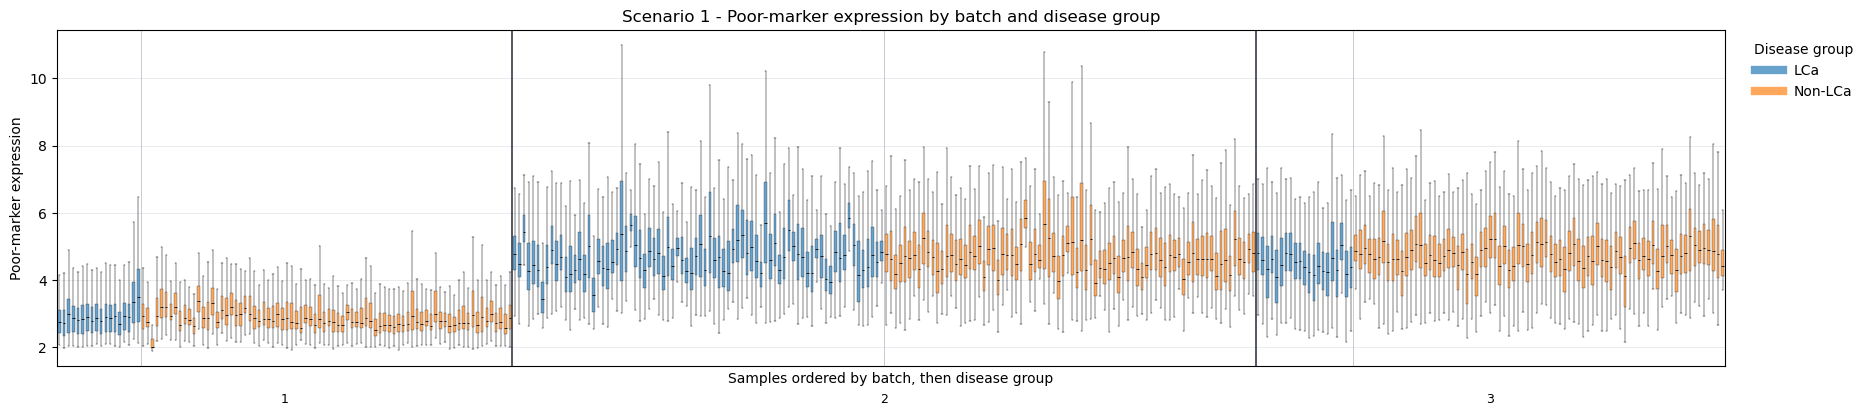

Pro 2-meta-batch QC


,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,3.934066,0.202673,NaN,NaN,NaN,MODERATE
1,batch_balance,max_batch_count / min_batch_count,3.871609,0.205271,NaN,NaN,NaN,MODERATE
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.16707,0.166281,4.261535e-18,MODERATE


class,LCa,Non-LCa
batch,,
batch_1,507,1634
batch_2,39,514


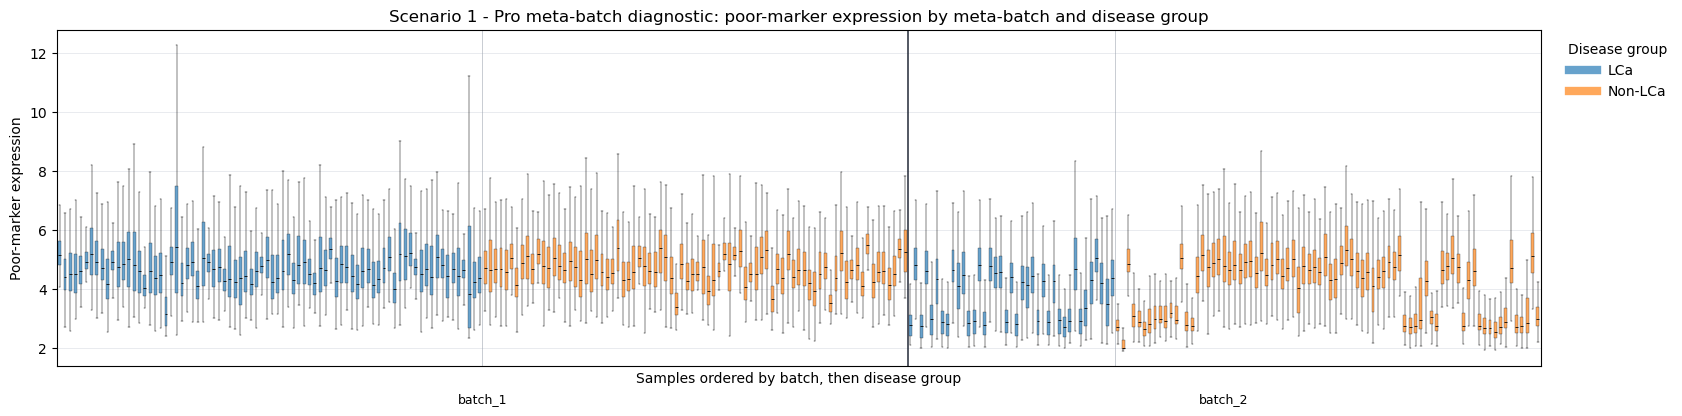

### Scenario 2

Original inferred 3-batch QC


,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,1.049451,0.487936,NaN,NaN,NaN,LOW
1,batch_balance,max_batch_count / min_batch_count,46.333333,0.016086,NaN,NaN,NaN,HIGH
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.46882,0.921348,3.919275e-54,HIGH


class,LCa,NTLD
batch,,
1,18,0
2,507,327
3,21,246


,retained_samples_for_plot,batch_class_strata,plot_file
0,279,5,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...


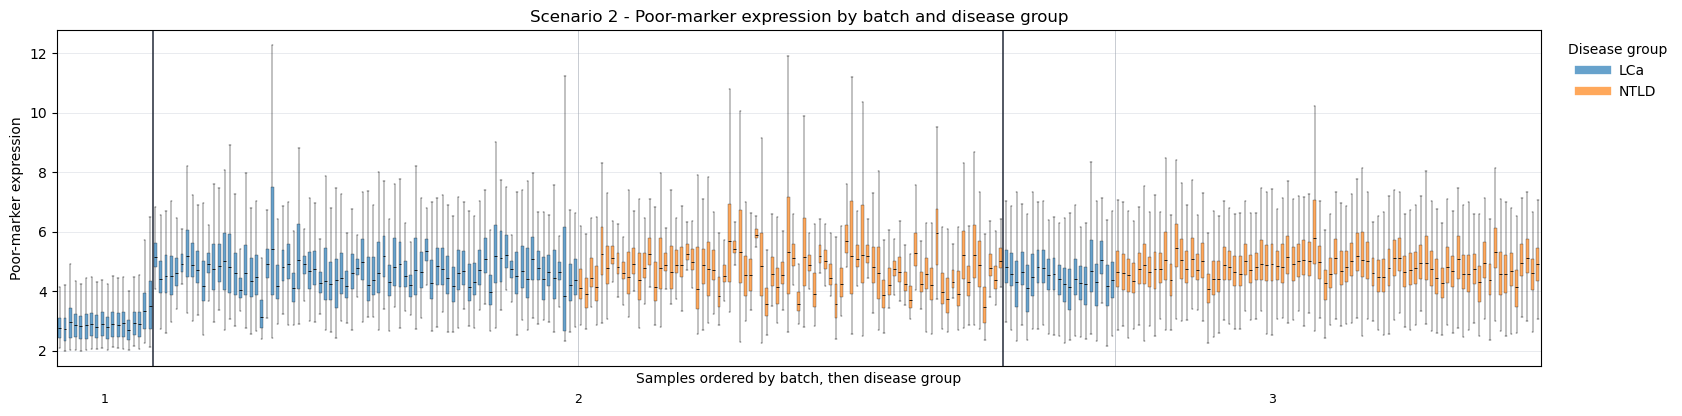

Pro 2-meta-batch QC


,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,1.049451,0.487936,NaN,NaN,NaN,LOW
1,batch_balance,max_batch_count / min_batch_count,2.926316,0.254692,NaN,NaN,NaN,MODERATE
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.4106,0.471072,6.251693e-43,HIGH


class,LCa,NTLD
batch,,
batch_1,507,327
batch_2,39,246


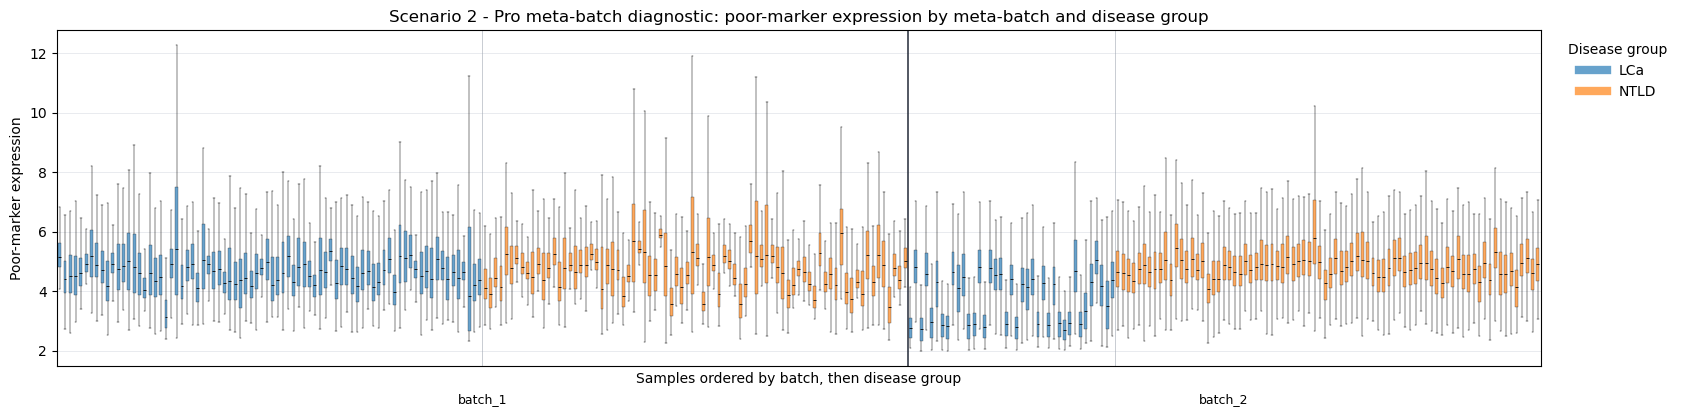

### Scenario 3

Original inferred 3-batch QC


,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,12.561404,0.073739,NaN,NaN,NaN,HIGH
1,batch_balance,max_batch_count / min_batch_count,6.418605,0.074170,NaN,NaN,NaN,HIGH
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.084747,0.072621,0.000242,LOW


class,Early-stage LCa,Non-LCa
batch,,
1,100,943
2,67,1037
3,4,168


,retained_samples_for_plot,batch_class_strata,plot_file
0,391,6,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...


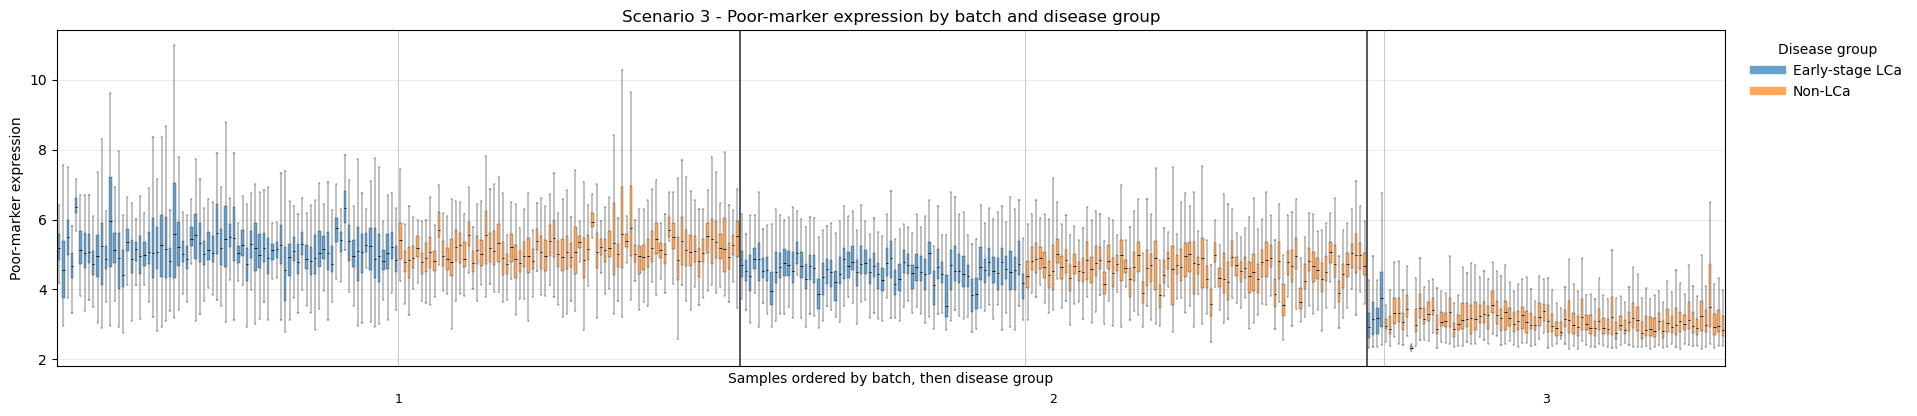

Pro 2-meta-batch QC


,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,12.561404,0.073739,NaN,NaN,NaN,HIGH
1,batch_balance,max_batch_count / min_batch_count,1.100543,0.476067,NaN,NaN,NaN,LOW
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.047599,0.024908,0.021894,LOW


class,Early-stage LCa,Non-LCa
batch,,
batch_1,67,1037
batch_2,104,1111


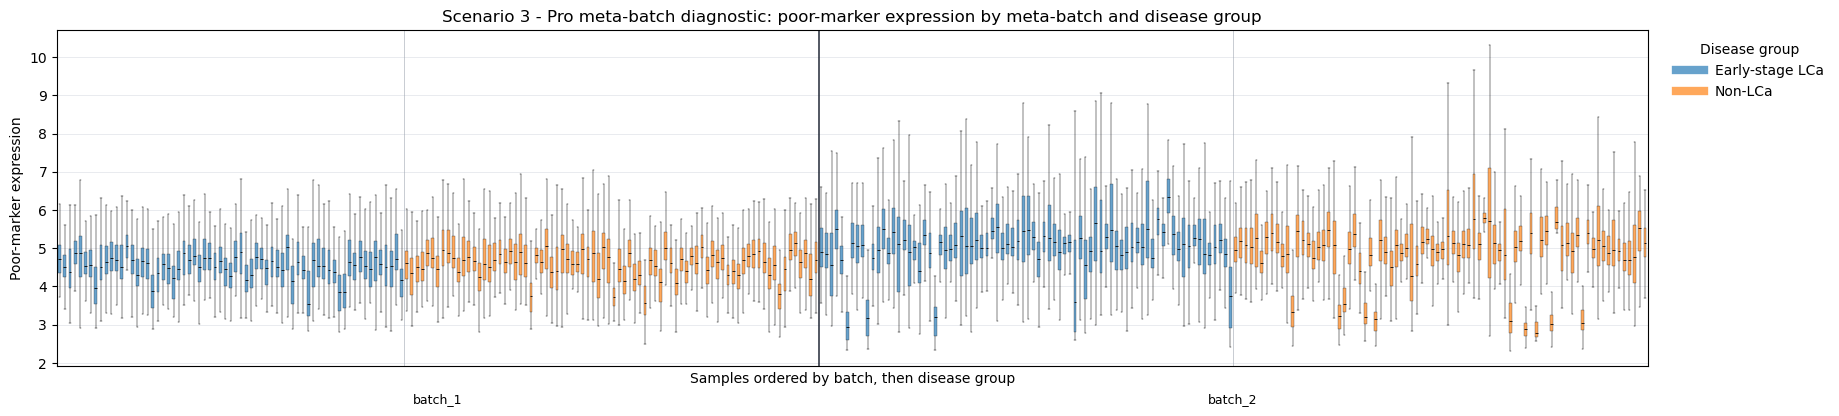

Interpretation note: if boxes for different disease classes within the same batch are similar, while the entire distribution shifts between batches, this supports the interpretation that batch-associated variation exceeds disease-label-associated variation in the poor-marker space.

In [16]:
JAMA_PRO_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
JAMA_QC_RESULTS = {}

for scenario_name, entry in JAMA_SCENARIO_DIAGNOSTICS.items():
    if Markdown is not None:
        display(Markdown(f"### {scenario_name}"))
    else:
        print(f"### {scenario_name}")

    scenario_qc_dir = JAMA_PRO_OUTPUT_ROOT / entry["output_name"] / "qc"
    scenario_qc_dir.mkdir(parents=True, exist_ok=True)

    qc_summary, batch_class_table = summarize_batch_structure(entry["qc_dataset"], scenario=scenario_name)
    qc_view = qc_summary[
        [
            "domain",
            "metric",
            "ratio",
            "minority_proportion",
            "cramers_v",
            "abs_prevalence_difference",
            "chi_square_p_value",
            "status",
        ]
    ]
    print("Original inferred 3-batch QC")
    display(qc_view)
    display(batch_class_table)
    qc_summary.to_csv(scenario_qc_dir / "batch_structure_qc_summary.csv", index=False)
    batch_class_table.to_csv(scenario_qc_dir / "batch_class_contingency.csv")
    qc_summary.to_csv(scenario_qc_dir / "original_batch_structure_qc_summary.csv", index=False)
    batch_class_table.to_csv(scenario_qc_dir / "original_batch_class_contingency.csv")

    fig, ax, ordered_samples = plot_poor_marker_samplewise_boxplot(
        entry["poor_expression"],
        entry["class_labels"],
        entry["inferred_batch_labels"],
        title=entry["title"],
        max_samples_per_stratum=JAMA_QC_BOXPLOT_MAX_SAMPLES_PER_STRATUM,
        seed=JAMA_STRUCTURE_SEED,
    )
    fig.savefig(scenario_qc_dir / "poor_marker_samplewise_boxplot.png", dpi=160, bbox_inches="tight")
    display(
        pd.DataFrame(
            [
                {
                    "retained_samples_for_plot": int(ordered_samples.shape[0]),
                    "batch_class_strata": int(ordered_samples.groupby(["batch", "class"]).ngroups),
                    "plot_file": str(scenario_qc_dir / "poor_marker_samplewise_boxplot.png"),
                }
            ]
        )
    )
    plt.show()

    meta_qc_summary, meta_batch_class_table = summarize_batch_structure(entry["meta_qc_dataset"], scenario=f"{scenario_name} Pro meta-batch")
    meta_qc_view = meta_qc_summary[
        [
            "domain",
            "metric",
            "ratio",
            "minority_proportion",
            "cramers_v",
            "abs_prevalence_difference",
            "chi_square_p_value",
            "status",
        ]
    ]
    print("Pro 2-meta-batch QC")
    display(meta_qc_view)
    display(meta_batch_class_table)
    assert meta_batch_class_table.shape == (2, 2)
    meta_qc_summary.to_csv(scenario_qc_dir / "meta_batch_structure_qc_summary.csv", index=False)
    meta_batch_class_table.to_csv(scenario_qc_dir / "meta_batch_class_contingency.csv")

    meta_fig, meta_ax, meta_ordered_samples = plot_poor_marker_samplewise_boxplot(
        entry["poor_expression"],
        entry["class_labels"],
        entry["meta_batch_labels"],
        title=entry["meta_title"],
        max_samples_per_stratum=JAMA_QC_BOXPLOT_MAX_SAMPLES_PER_STRATUM,
        seed=JAMA_STRUCTURE_SEED,
    )
    meta_fig.savefig(scenario_qc_dir / "meta_batch_samplewise_boxplot.png", dpi=160, bbox_inches="tight")
    plt.show()

    provenance = pd.DataFrame(
        {
            "sample_id": entry["poor_expression"].columns.astype(str),
            "inferred_batch": entry["inferred_batch_labels"].astype(int).to_numpy(),
            "meta_batch": entry["meta_batch_labels"].astype(str).to_numpy(),
            "modeling_class": entry["class_labels"].astype(str).to_numpy(),
        },
        index=entry["poor_expression"].columns,
    )
    provenance.to_csv(scenario_qc_dir / "batch_mapping_provenance.csv", index=False)

    JAMA_QC_RESULTS[scenario_name] = {
        "qc_summary": qc_summary,
        "batch_class_table": batch_class_table,
        "ordered_samples": ordered_samples,
        "meta_qc_summary": meta_qc_summary,
        "meta_batch_class_table": meta_batch_class_table,
        "meta_ordered_samples": meta_ordered_samples,
        "provenance": provenance,
        "qc_dir": scenario_qc_dir,
    }

if Markdown is not None:
    display(Markdown(
        "Interpretation note: if boxes for different disease classes within the same batch are similar, "
        "while the entire distribution shifts between batches, this supports the interpretation that "
        "batch-associated variation exceeds disease-label-associated variation in the poor-marker space."
    ))
else:
    print(
        "Interpretation note: if boxes for different disease classes within the same batch are similar, "
        "while the entire distribution shifts between batches, this supports the interpretation that "
        "batch-associated variation exceeds disease-label-associated variation in the poor-marker space."
    )


## JAMA Pro experiment registry


In [17]:
JAMA_PRO_EXPERIMENTS = {
    "s1_broad": {
        "dataset": MolecularDataset(
            expression=s1_broad_dataset.expression,
            class_labels=s1_broad_dataset.class_labels,
            batch_labels=JAMA_META_BATCH_LABELS["Scenario 1"],
        ),
        "scenario": "s1",
        "feature_set": "broad",
        "output_name": "jama_pro_s1_broad",
        "inferred_batch_labels": s1_batch_labels,
    },
    "s2_broad": {
        "dataset": MolecularDataset(
            expression=s2_broad_dataset.expression,
            class_labels=s2_broad_dataset.class_labels,
            batch_labels=JAMA_META_BATCH_LABELS["Scenario 2"],
        ),
        "scenario": "s2",
        "feature_set": "broad",
        "output_name": "jama_pro_s2_broad",
        "inferred_batch_labels": s2_batch_labels,
    },
    "s3_broad": {
        "dataset": MolecularDataset(
            expression=s3_broad_dataset.expression,
            class_labels=s3_broad_dataset.class_labels,
            batch_labels=JAMA_META_BATCH_LABELS["Scenario 3"],
        ),
        "scenario": "s3",
        "feature_set": "broad",
        "output_name": "jama_pro_s3_broad",
        "inferred_batch_labels": s3_batch_labels,
    },
}

JAMA_PRO_RUN_ORDER = ("s1_broad", "s2_broad", "s3_broad")
assert set(JAMA_PRO_RUN_ORDER) == set(JAMA_PRO_EXPERIMENTS)
assert all("jama_pro" in entry["output_name"] for entry in JAMA_PRO_EXPERIMENTS.values())
assert all(entry["output_name"] not in {"jama_s1_broad", "jama_s2_broad", "jama_s3_broad"} for entry in JAMA_PRO_EXPERIMENTS.values())

for experiment_name, entry in JAMA_PRO_EXPERIMENTS.items():
    dataset = entry["dataset"]
    inferred = entry["inferred_batch_labels"]
    validate_molecular_dataset(dataset)
    validate_jama_meta_batch_mapping(inferred, dataset.batch_labels, dataset.class_labels, dataset.expression, experiment_name)
    assert set(dataset.batch_labels.unique()) == {"batch_1", "batch_2"}
    assert dataset.expression.columns.equals(dataset.class_labels.index)
    assert dataset.expression.columns.equals(dataset.batch_labels.index)
    assert dataset.expression.columns.equals(inferred.index)

for experiment_name, entry in JAMA_PRO_EXPERIMENTS.items():
    dataset = entry["dataset"]
    print(
        f"{experiment_name}: {dataset.expression.shape[0]} features x {dataset.expression.shape[1]} samples; "
        f"classes={dataset.class_labels.value_counts().sort_index().to_dict()}; "
        f"meta_batches={dataset.batch_labels.value_counts().sort_index().to_dict()}; "
        f"output={entry['output_name']}"
    )


s1_broad: 152 features x 2694 samples; classes={0: 2148, 1: 546}; meta_batches={'batch_1': 2141, 'batch_2': 553}; output=jama_pro_s1_broad
s2_broad: 152 features x 1119 samples; classes={0: 573, 1: 546}; meta_batches={'batch_1': 834, 'batch_2': 285}; output=jama_pro_s2_broad
s3_broad: 200 features x 2319 samples; classes={0: 2148, 1: 171}; meta_batches={'batch_1': 1104, 'batch_2': 1215}; output=jama_pro_s3_broad


## Pro execution: natural and class-stratified bidirectional evaluation

Full Pro execution is disabled by default. When enabled, outputs are isolated under `results_pro_jama/`, use JAMA-Pro-specific output names, run both prevalence modes, and use the shared Pro runtime artifact saver.


Loaded previous JAMA Pro smoke-test checkpoint:
C:\Users\apple\Desktop\RNASeq_with_Python\2Jama\results_pro_jama\smoke_test\smoke_test_passed_manifest.csv
Smoke checkpoint exists : True
Smoke manifest rows     : 2
Smoke test passed       : True
s1_broad | natural
s1_broad | class_stratified
s2_broad | natural
s2_broad | class_stratified
s3_broad | natural
s3_broad | class_stratified
JAMA Pro elapsed time: 1200.70 minutes


,experiment,output_name,prevalence_mode,status,n_raw_rows,output_directory
0,s1_broad,jama_pro_s1_broad,natural,complete,2000,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...
1,s1_broad,jama_pro_s1_broad,class_stratified,complete,2000,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...
2,s2_broad,jama_pro_s2_broad,natural,complete,2000,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...
3,s2_broad,jama_pro_s2_broad,class_stratified,complete,2000,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...
4,s3_broad,jama_pro_s3_broad,natural,complete,2000,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...
5,s3_broad,jama_pro_s3_broad,class_stratified,complete,2000,C:\Users\apple\Desktop\RNASeq_with_Python\2Jam...


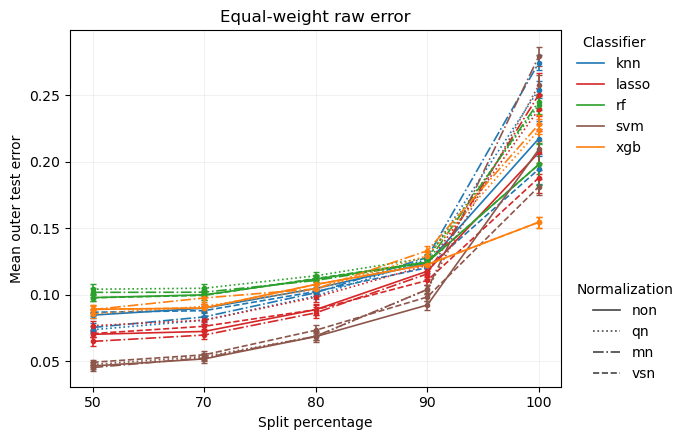

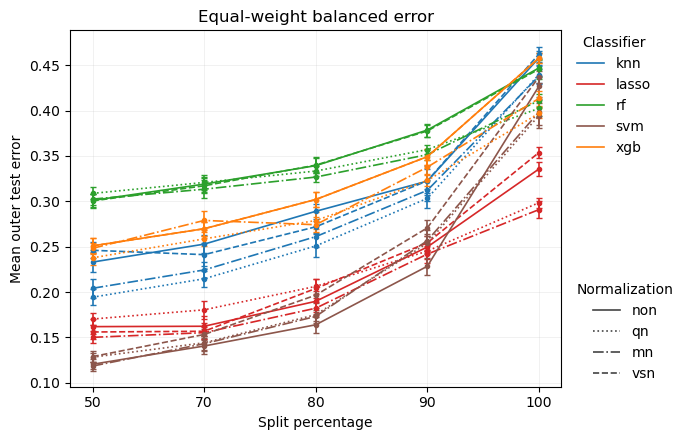

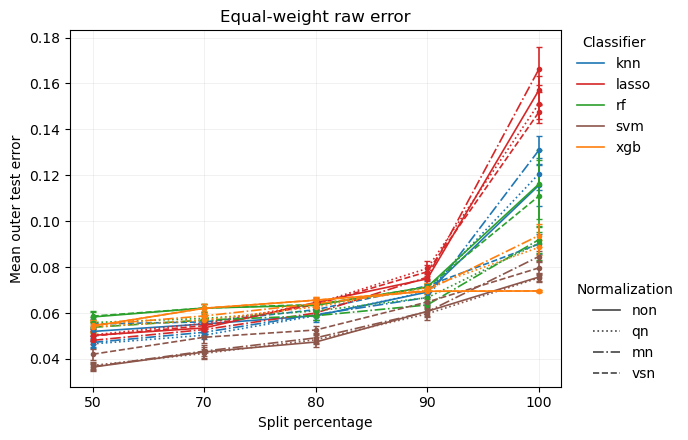

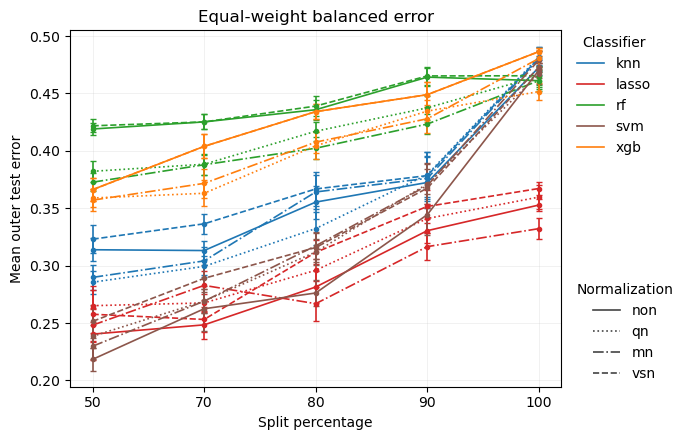

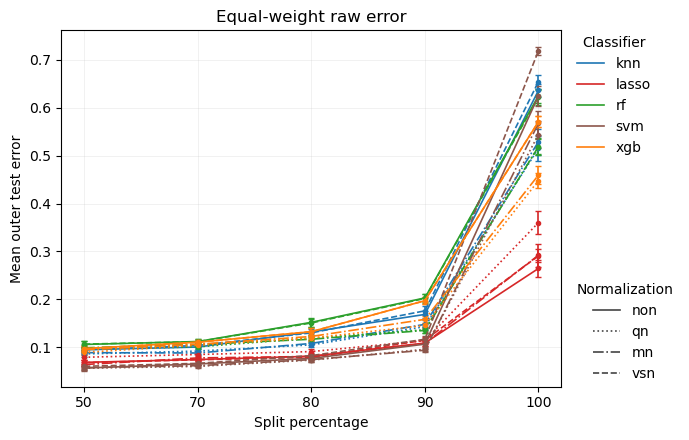

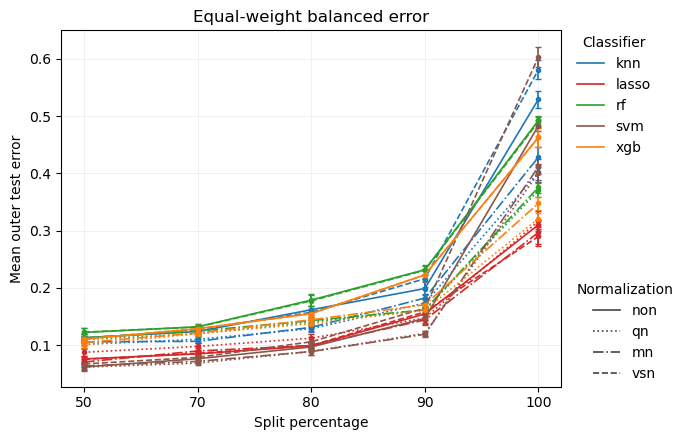

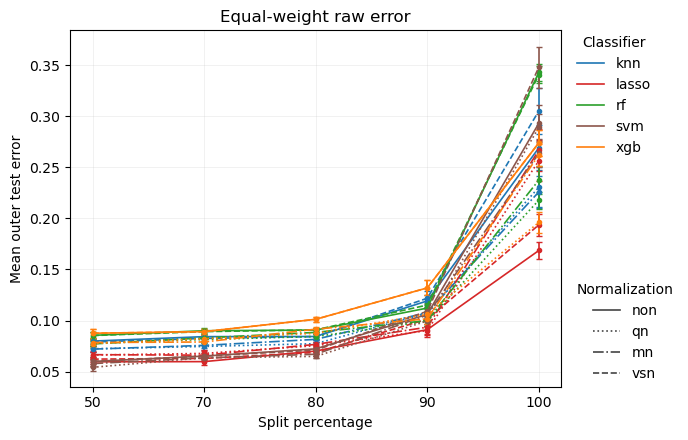

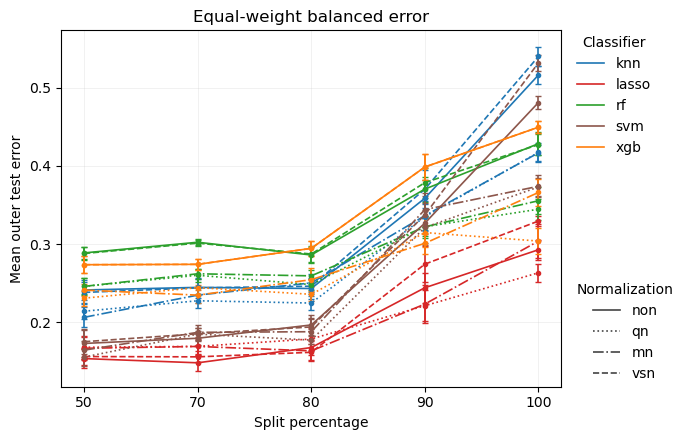

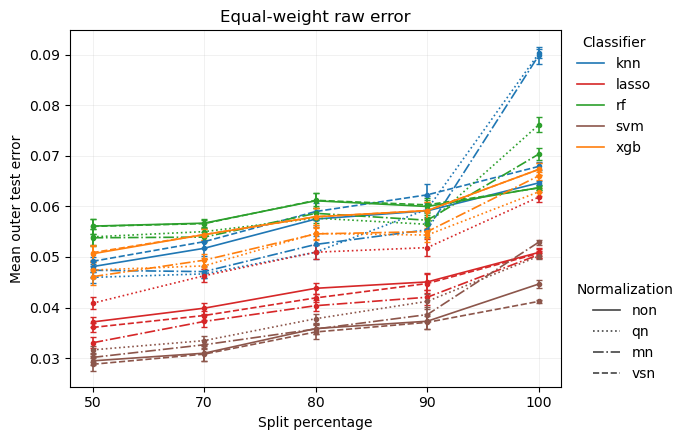

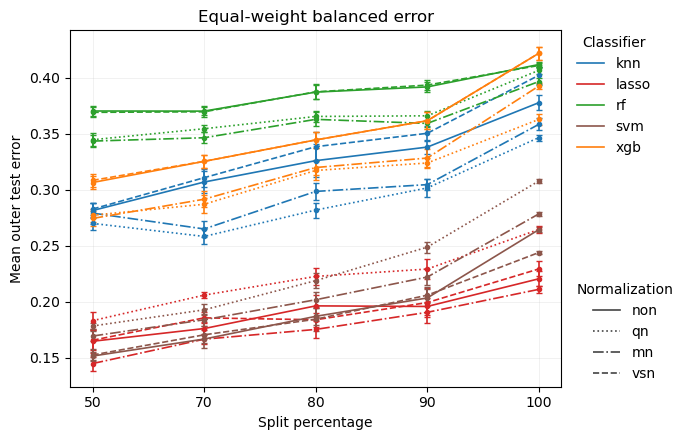

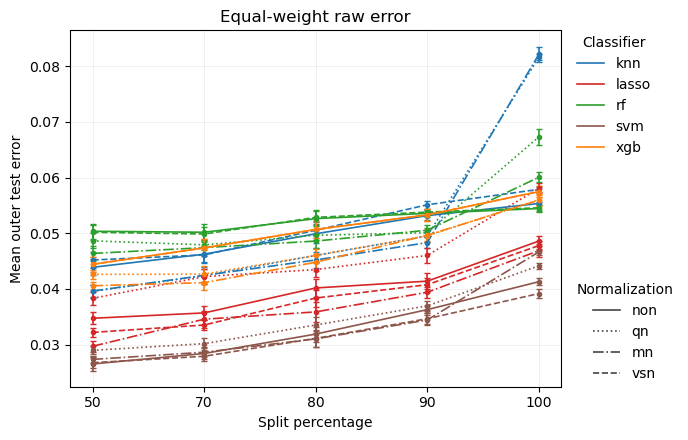

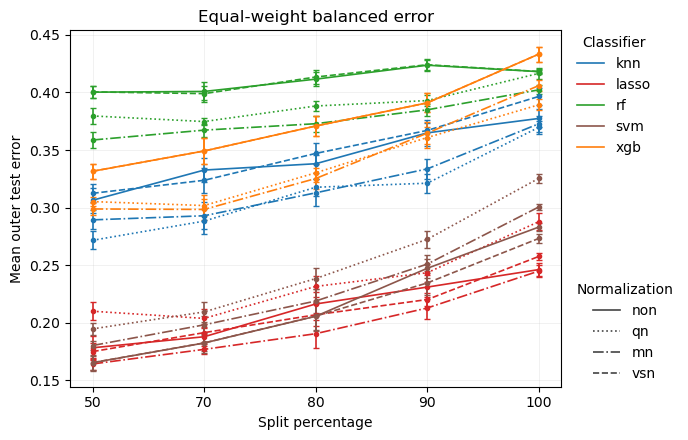

In [26]:
# ======================================================================
# JAMA PRO — smoke test + optional full run
# ======================================================================

RUN_JAMA_PRO = True
RUN_JAMA_PRO_SMOKE_TEST = False
JAMA_PRO_TEST_MODE = False

JAMA_PRO_TIMES = 10
JAMA_PRO_SPLITS = (50, 70, 80, 90, 100)
JAMA_PRO_NORMALIZATIONS = ("non", "qn", "mn", "vsn")
JAMA_PRO_CLASSIFIERS = ("knn", "lasso", "rf", "svm", "xgb")
JAMA_PRO_SEED = 2024
JAMA_PRO_PREVALENCE_MODES = ("natural", "class_stratified")


# ----------------------------------------------------------------------
# Output-root validation
# ----------------------------------------------------------------------

if BASE_DIR.resolve() not in (
    JAMA_PRO_OUTPUT_ROOT.resolve(),
    *JAMA_PRO_OUTPUT_ROOT.resolve().parents,
):
    raise ValueError(
        f"JAMA_PRO_OUTPUT_ROOT must stay inside 2Jama: "
        f"{JAMA_PRO_OUTPUT_ROOT}"
    )

if JAMA_PRO_OUTPUT_ROOT.name in {
    "results_r_parity_test",
    "results",
}:
    raise ValueError(
        "JAMA Pro output root must not collide with original JAMA outputs"
    )


# ----------------------------------------------------------------------
# Persistent smoke-test checkpoint
# ----------------------------------------------------------------------

smoke_root = JAMA_PRO_OUTPUT_ROOT / "smoke_test"
smoke_root.mkdir(parents=True, exist_ok=True)

# Explicit notebook-controlled checkpoint.
# This avoids depending on whatever manifest filename the shared runtime uses.
SMOKE_CHECKPOINT = smoke_root / "smoke_test_passed_manifest.csv"


# ----------------------------------------------------------------------
# Optional smoke test
# ----------------------------------------------------------------------

if RUN_JAMA_PRO_SMOKE_TEST:

    smoke_experiments = {
        "s3_broad_smoke": {
            **{
                key: value
                for key, value in JAMA_PRO_EXPERIMENTS["s3_broad"].items()
                if key != "inferred_batch_labels"
            },
            "output_name": "jama_pro_smoke_s3_broad",
        }
    }

    JAMA_PRO_SMOKE_MANIFEST = run_ssv_pro_experiment_batch(
        experiments=smoke_experiments,
        output_root=smoke_root,
        experiment_order=("s3_broad_smoke",),
        n_repetitions=2,
        split_combination=(50, 100),
        normalization_methods=("non",),
        classifier_methods=("knn",),
        seed=JAMA_PRO_SEED,
        prevalence_modes=JAMA_PRO_PREVALENCE_MODES,
        data_type_rnaseq=DATA_TYPE_RNASEQ,
        progress=True,
    )

    # Basic smoke-manifest checks
    assert not JAMA_PRO_SMOKE_MANIFEST.empty
    assert "status" in JAMA_PRO_SMOKE_MANIFEST.columns
    assert JAMA_PRO_SMOKE_MANIFEST["status"].eq("complete").all()

    # Artifact/content checks
    for _, row in JAMA_PRO_SMOKE_MANIFEST.iterrows():

        protocol_dir = Path(row["output_directory"])

        raw_path = protocol_dir / "raw_results.csv"
        assert raw_path.exists()

        raw = pd.read_csv(raw_path)

        assert {
            "raw_error",
            "balanced_error",
            "direction",
            "prevalence_mode",
        } <= set(raw.columns)

        successful_directions = set(
            raw.loc[
                raw["status"].eq("success"),
                "direction",
            ]
        )

        assert successful_directions == {
            "batch_1_to_batch_2",
            "batch_2_to_batch_1",
        }

        assert set(raw["prevalence_mode"].dropna()) == {
            row["prevalence_mode"]
        }

        assert (
            protocol_dir
            / "equal_weight_raw_error_curve.png"
        ).exists()

        assert (
            protocol_dir
            / "equal_weight_balanced_error_curve.png"
        ).exists()

    # Persist a verified PASS checkpoint explicitly.
    JAMA_PRO_SMOKE_MANIFEST.to_csv(
        SMOKE_CHECKPOINT,
        index=False,
    )

    print("JAMA Pro smoke test: PASS")
    print(f"Smoke checkpoint saved to: {SMOKE_CHECKPOINT}")
    display(JAMA_PRO_SMOKE_MANIFEST)


# ----------------------------------------------------------------------
# Recover previous smoke-test checkpoint when smoke test is not rerun
# ----------------------------------------------------------------------

elif SMOKE_CHECKPOINT.exists():

    JAMA_PRO_SMOKE_MANIFEST = pd.read_csv(
        SMOKE_CHECKPOINT
    )

    print("Loaded previous JAMA Pro smoke-test checkpoint:")
    print(SMOKE_CHECKPOINT)


else:

    JAMA_PRO_SMOKE_MANIFEST = pd.DataFrame()


# ----------------------------------------------------------------------
# Validate previously completed smoke test before full run
# ----------------------------------------------------------------------

smoke_test_passed = (
    not JAMA_PRO_SMOKE_MANIFEST.empty
    and "status" in JAMA_PRO_SMOKE_MANIFEST.columns
    and JAMA_PRO_SMOKE_MANIFEST["status"].eq("complete").all()
)

print(f"Smoke checkpoint exists : {SMOKE_CHECKPOINT.exists()}")
print(f"Smoke manifest rows     : {len(JAMA_PRO_SMOKE_MANIFEST)}")
print(f"Smoke test passed       : {smoke_test_passed}")


# ----------------------------------------------------------------------
# Optional full JAMA Pro execution
# ----------------------------------------------------------------------

if RUN_JAMA_PRO:

    if not smoke_test_passed:
        raise RuntimeError(
            "No completed JAMA Pro smoke-test checkpoint was found. "
            "Run once with RUN_JAMA_PRO=False and "
            "RUN_JAMA_PRO_SMOKE_TEST=True, confirm PASS, "
            "then rerun with RUN_JAMA_PRO=True and "
            "RUN_JAMA_PRO_SMOKE_TEST=False."
        )

    pro_start = perf_counter()

    if JAMA_PRO_TEST_MODE:

        active_experiments = {
            "s3_broad": {
                key: value
                for key, value in JAMA_PRO_EXPERIMENTS["s3_broad"].items()
                if key != "inferred_batch_labels"
            }
        }

        active_order = ("s3_broad",)
        active_times = 2
        active_splits = (50, 100)
        active_normalizations = ("non",)
        active_classifiers = ("knn",)

    else:

        active_experiments = {
            name: {
                key: value
                for key, value in entry.items()
                if key != "inferred_batch_labels"
            }
            for name, entry in JAMA_PRO_EXPERIMENTS.items()
        }

        active_order = JAMA_PRO_RUN_ORDER
        active_times = JAMA_PRO_TIMES
        active_splits = JAMA_PRO_SPLITS
        active_normalizations = JAMA_PRO_NORMALIZATIONS
        active_classifiers = JAMA_PRO_CLASSIFIERS

    jama_pro_manifest = run_ssv_pro_experiment_batch(
        experiments=active_experiments,
        output_root=JAMA_PRO_OUTPUT_ROOT,
        experiment_order=active_order,
        n_repetitions=active_times,
        split_combination=active_splits,
        normalization_methods=active_normalizations,
        classifier_methods=active_classifiers,
        seed=JAMA_PRO_SEED,
        prevalence_modes=JAMA_PRO_PREVALENCE_MODES,
        data_type_rnaseq=DATA_TYPE_RNASEQ,
        progress=True,
    )

    assert not jama_pro_manifest.empty
    assert "status" in jama_pro_manifest.columns
    assert jama_pro_manifest["status"].eq("complete").all()

    for _, row in jama_pro_manifest.iterrows():

        raw_path = (
            Path(row["output_directory"])
            / "raw_results.csv"
        )

        assert raw_path.exists()

        raw = pd.read_csv(raw_path)

        assert {
            "raw_error",
            "balanced_error",
        } <= set(raw.columns)

    elapsed_seconds = perf_counter() - pro_start

    print(
        f"JAMA Pro elapsed time: "
        f"{elapsed_seconds / 60:.2f} minutes"
    )

    display(jama_pro_manifest)


else:

    jama_pro_manifest = pd.DataFrame()

    print(
        "Full JAMA Pro execution skipped; "
        "RUN_JAMA_PRO is False."
    )

    print(
        f"Full outputs will be written under: "
        f"{JAMA_PRO_OUTPUT_ROOT}"
    )

    print(
        f"Prevalence modes supported: "
        f"{JAMA_PRO_PREVALENCE_MODES}"
    )

    print(
        f"Shared Pro metrics: "
        f"{PRO_METRICS}"
    )

## Concise completion audit


In [27]:
audit_rows = []


def audit(name, condition):
    audit_rows.append({"check": name, "status": "PASS" if bool(condition) else "FAIL"})


audit("new_pro_notebook_path_isolated", PRO_NOTEBOOK_PATH.name == "SSV_Jama_Python_pro.ipynb")
audit("baseline_source_not_overwritten", BASELINE_SOURCE_NOTEBOOK.resolve() != PRO_NOTEBOOK_PATH.resolve())
audit("shared_pro_runtime_loaded", all(name in globals() for name in _RUNTIME_REQUIRED))
audit("three_jama_scenarios_registered", set(JAMA_PRO_EXPERIMENTS) == {"s1_broad", "s2_broad", "s3_broad"})
audit("diagnostics_registry_has_three_scenarios", set(JAMA_SCENARIO_DIAGNOSTICS) == {"Scenario 1", "Scenario 2", "Scenario 3"})
audit("original_3batch_labels_visible", all(set(entry["inferred_batch_labels"].astype(int).unique()) == {1, 2, 3} for entry in JAMA_SCENARIO_DIAGNOSTICS.values()))
audit("deterministic_3_to_2_mapping", all(
    entry["meta_batch_labels"].loc[entry["inferred_batch_labels"].astype(int).eq(2)].eq("batch_1").all()
    and entry["meta_batch_labels"].loc[entry["inferred_batch_labels"].astype(int).isin([1, 3])].eq("batch_2").all()
    for entry in JAMA_SCENARIO_DIAGNOSTICS.values()
))
audit("pro_datasets_have_two_meta_batches", all(set(entry["dataset"].batch_labels.unique()) == {"batch_1", "batch_2"} for entry in JAMA_PRO_EXPERIMENTS.values()))
audit("no_sample_loss_or_reordering", all(
    entry["dataset"].expression.columns.equals(entry["dataset"].class_labels.index)
    and entry["dataset"].expression.columns.equals(entry["dataset"].batch_labels.index)
    and entry["dataset"].expression.columns.equals(entry["inferred_batch_labels"].index)
    for entry in JAMA_PRO_EXPERIMENTS.values()
))
audit("original_qc_tables_saved", all((entry["qc_dir"] / "original_batch_structure_qc_summary.csv").exists() for entry in JAMA_QC_RESULTS.values()))
audit("original_batch_class_tables_saved", all((entry["qc_dir"] / "original_batch_class_contingency.csv").exists() for entry in JAMA_QC_RESULTS.values()))
audit("meta_qc_tables_saved", all((entry["qc_dir"] / "meta_batch_structure_qc_summary.csv").exists() for entry in JAMA_QC_RESULTS.values()))
audit("meta_batch_class_tables_saved", all((entry["qc_dir"] / "meta_batch_class_contingency.csv").exists() for entry in JAMA_QC_RESULTS.values()))
audit("samplewise_boxplots_saved", all((entry["qc_dir"] / "poor_marker_samplewise_boxplot.png").exists() for entry in JAMA_QC_RESULTS.values()))
audit("meta_batch_boxplots_saved", all((entry["qc_dir"] / "meta_batch_samplewise_boxplot.png").exists() for entry in JAMA_QC_RESULTS.values()))
audit("mapping_provenance_saved", all((entry["qc_dir"] / "batch_mapping_provenance.csv").exists() for entry in JAMA_QC_RESULTS.values()))
audit("meta_tables_are_2x2", all(entry["meta_batch_class_table"].shape == (2, 2) for entry in JAMA_QC_RESULTS.values()))
audit("prevalence_modes_supported", set(JAMA_PRO_PREVALENCE_MODES) == {"natural", "class_stratified"})
audit("bidirectional_pro_engine_available", "run_ssv_pro_bidirectional" in globals())
audit("smoke_test_passed", not JAMA_PRO_SMOKE_MANIFEST.empty and JAMA_PRO_SMOKE_MANIFEST["status"].eq("complete").all())
audit("raw_and_balanced_error_supported", {"raw_error", "balanced_error"} <= set(PRO_METRICS))
audit("split_percentages_preserved", JAMA_PRO_SPLITS == (50, 70, 80, 90, 100))
audit("pro_outputs_are_jama_specific", JAMA_PRO_OUTPUT_ROOT.name == "results_pro_jama" and all("jama_pro" in entry["output_name"] for entry in JAMA_PRO_EXPERIMENTS.values()))
audit("original_output_names_not_reused", all(entry["output_name"] not in {"jama_s1_broad", "jama_s2_broad", "jama_s3_broad"} for entry in JAMA_PRO_EXPERIMENTS.values()))

audit_table = pd.DataFrame(audit_rows)
display(audit_table)
if not audit_table["status"].eq("PASS").all():
    raise AssertionError("One or more JAMA Pro audit checks failed")
print("JAMA Pro 3-to-2 meta-batch audit: PASS")


,check,status
0,new_pro_notebook_path_isolated,PASS
1,baseline_source_not_overwritten,PASS
2,shared_pro_runtime_loaded,PASS
3,three_jama_scenarios_registered,PASS
4,diagnostics_registry_has_three_scenarios,PASS
5,original_3batch_labels_visible,PASS
6,deterministic_3_to_2_mapping,PASS
7,pro_datasets_have_two_meta_batches,PASS
8,no_sample_loss_or_reordering,PASS
9,original_qc_tables_saved,PASS


JAMA Pro 3-to-2 meta-batch audit: PASS
